# SEMMA project: which Lending Club loans will charge off?

One notebook, one section per SEMMA stage: **S**ample, **E**xplore, **M**odify, **M**odel, **A**ssess. SEMMA (SAS Institute) organizes Enterprise Miner's tools and has no business-understanding or deployment phase, so the problem framing before Sample and the deployment after Assess are labelled **extensions**.
**Data:** All Lending Club loan data, Kaggle `wordsforthewise/lending-club`, file `accepted_2007_to_2018Q4.csv.gz` (CC0).
**Target:** Charged Off or Default = 1, Fully Paid = 0, using only what is known at origination.
In Colab, add a Kaggle API token as the secret `KAGGLE_API_TOKEN`. The first run reads the 2.2M-row file in chunks (a few minutes) and caches results in `data/`.

In [1]:
import sys, os, json, subprocess, warnings, random, hashlib, datetime, time
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-learn==1.9.1", "lightgbm==4.7.0", "pandas==3.1.1", "pyarrow", "scipy"], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.width", 170, "display.max_columns", 40, "display.max_rows", 200)

cwd = Path.cwd()
ROOT = Path("/content/semma_lc") if IN_COLAB else (cwd.parent if cwd.name == "notebooks" else cwd)
DATA, ART, FIG, DEP = ROOT / "data", ROOT / "artifacts", ROOT / "artifacts" / "figures", ROOT / "deployment"
for p in (DATA, FIG, DEP):
    p.mkdir(parents=True, exist_ok=True)
import sklearn, lightgbm
print("python", sys.version.split()[0], "| pandas", pd.__version__, "| sklearn", sklearn.__version__, "| lightgbm", lightgbm.__version__, "| seed", SEED)

python 3.12.13 | pandas 3.1.1 | sklearn 1.9.1 | lightgbm 4.7.0 | seed 42


In [2]:
MODULE_SRC = r'''"""Feature engineering and weight-of-evidence (WoE) helpers for the Lending Club SEMMA project.
Used by the notebook (training) and the batch scoring script, so both build features the same way.
Everything fitted (bin edges, WoE values) is learned from training rows only."""
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

EMP_MAP = {"< 1 year": 0, "1 year": 1, "2 years": 2, "3 years": 3, "4 years": 4, "5 years": 5, "6 years": 6,
           "7 years": 7, "8 years": 8, "9 years": 9, "10+ years": 10}


def add_features(df: pd.DataFrame) -> pd.DataFrame:
    """Row-wise features known at origination. Needs `issue_d` (application month, e.g. 'Jan-2013')."""
    x = df.copy()
    issue = pd.to_datetime(x["issue_d"], format="%b-%Y")
    earliest = pd.to_datetime(x["earliest_cr_line"], format="%b-%Y")
    x["credit_hist_years"] = ((issue - earliest).dt.days / 365.25).astype(float)
    x["fico"] = (pd.to_numeric(x["fico_range_low"]) + pd.to_numeric(x["fico_range_high"])) / 2
    inc = pd.to_numeric(x["annual_inc"], errors="coerce").clip(lower=1)
    x["log_income"] = np.log(inc)
    x["log_loan_amnt"] = np.log(pd.to_numeric(x["loan_amnt"], errors="coerce").clip(lower=1))
    x["loan_to_income"] = pd.to_numeric(x["loan_amnt"], errors="coerce") / inc
    x["emp_length_yrs"] = x["emp_length"].map(EMP_MAP).astype(float)
    x["revol_bal_to_income"] = pd.to_numeric(x["revol_bal"], errors="coerce") / inc
    x["dti"] = pd.to_numeric(x["dti"], errors="coerce")
    x["revol_util"] = pd.to_numeric(x["revol_util"], errors="coerce")
    return x


class WoEBinner(BaseEstimator, TransformerMixin):
    """Quantile-bin numeric columns (plus a MISSING bin) and group rare categories, then replace each bin by
    its weight of evidence ln(share of good / share of bad). Fit on training rows only."""

    def __init__(self, num_cols, cat_cols, n_bins=10, min_cat=0.005, smooth=0.5):
        self.num_cols = num_cols
        self.cat_cols = cat_cols
        self.n_bins = n_bins
        self.min_cat = min_cat
        self.smooth = smooth

    def _num_bin(self, v, edges):
        v = pd.to_numeric(v, errors="coerce")
        return np.where(v.isna(), -1, np.searchsorted(edges, v.fillna(0).values, side="right"))

    def _cat_bin(self, v, keep):
        v = v.astype("object").where(v.notna(), "MISSING")
        return v.where(v.isin(keep), "OTHER").astype(str).values

    def fit(self, X, y):
        y = np.asarray(y).astype(int)
        self.bad_, self.good_ = float(y.sum()), float((1 - y).sum())
        self.edges_, self.keep_, self.woe_, self.iv_, rows = {}, {}, {}, {}, []
        s = self.smooth
        for c in self.num_cols:
            v = pd.to_numeric(X[c], errors="coerce")
            self.edges_[c] = np.unique(np.nanquantile(v, np.linspace(0, 1, self.n_bins + 1)[1:-1]))
            b = self._num_bin(X[c], self.edges_[c])
            self.woe_[c], self.iv_[c] = self._woe(b, y, c, rows, kind="num")
        for c in self.cat_cols:
            share = X[c].astype("object").where(X[c].notna(), "MISSING").value_counts(normalize=True)
            self.keep_[c] = set(share[share >= self.min_cat].index)
            b = self._cat_bin(X[c], self.keep_[c])
            self.woe_[c], self.iv_[c] = self._woe(b, y, c, rows, kind="cat")
        self.bin_table_ = pd.DataFrame(rows)
        return self

    def _woe(self, b, y, c, rows, kind):
        s = self.smooth
        out, iv = {}, 0.0
        for k in pd.unique(b):
            m = b == k
            bad, good = y[m].sum(), (1 - y[m]).sum()
            w = float(np.log(((good + s) / (self.good_ + s)) / ((bad + s) / (self.bad_ + s))))
            out[k] = w
            part = ((good + s) / (self.good_ + s) - (bad + s) / (self.bad_ + s)) * w
            iv += part
            rows.append({"variable": c, "kind": kind, "bin": k, "loans": int(m.sum()), "bad_rate": float(y[m].mean()), "woe": w, "iv_part": float(part)})
        return out, float(iv)

    def transform(self, X):
        out = {}
        for c in self.num_cols:
            b = self._num_bin(X[c], self.edges_[c])
            out[c + "_woe"] = pd.Series(b, index=X.index).map(self.woe_[c]).fillna(0.0).values
        for c in self.cat_cols:
            b = self._cat_bin(X[c], self.keep_[c])
            out[c + "_woe"] = pd.Series(b, index=X.index).map(self.woe_[c]).fillna(0.0).values
        return pd.DataFrame(out, index=X.index)

    def set_output(self, *, transform=None):
        return self

    def get_feature_names_out(self, input_features=None):
        return np.array([c + "_woe" for c in list(self.num_cols) + list(self.cat_cols)], dtype=object)


def iv_table(X, y, num_cols, cat_cols, n_bins=10):
    """Information value of each variable on the given rows."""
    wb = WoEBinner(num_cols, cat_cols, n_bins=n_bins).fit(X, y)
    t = pd.DataFrame({"variable": list(wb.iv_), "iv": list(wb.iv_.values())}).sort_values("iv", ascending=False).reset_index(drop=True)
    t["strength"] = pd.cut(t.iv, [-1, 0.02, 0.1, 0.3, 0.5, 100], labels=["useless", "weak", "medium", "strong", "suspiciously strong"])
    return t


def ks_stat(y, p):
    """Kolmogorov-Smirnov statistic between the score distributions of bad and good loans (ties handled by the ROC curve)."""
    from sklearn.metrics import roc_curve
    fpr, tpr, _ = roc_curve(np.asarray(y), np.asarray(p))
    return float(np.max(tpr - fpr))


class TreePrep(BaseEstimator, TransformerMixin):
    """Preparation for tree and boosted models: numeric columns clipped at training quantiles (NaN kept),
    categorical columns ordinal-coded (unseen -> -1), and a missing-indicator for numeric columns that are
    missing in at least `miss_min` of the training rows. Fit on training rows only."""

    def __init__(self, num_cols, cat_cols, clip=(0.001, 0.999), miss_min=0.01):
        self.num_cols = num_cols
        self.cat_cols = cat_cols
        self.clip = clip
        self.miss_min = miss_min

    def fit(self, X, y=None):
        num = X[self.num_cols].apply(pd.to_numeric, errors="coerce")
        self.lo_ = num.quantile(self.clip[0])
        self.hi_ = num.quantile(self.clip[1])
        self.miss_cols_ = [c for c in self.num_cols if num[c].isna().mean() >= self.miss_min]
        self.cat_map_ = {c: {v: i for i, v in enumerate(sorted(X[c].dropna().astype(str).unique()))} for c in self.cat_cols}
        return self

    def transform(self, X):
        num = X[self.num_cols].apply(pd.to_numeric, errors="coerce")
        out = num.clip(self.lo_, self.hi_, axis=1).astype("float32")
        for c in self.miss_cols_:
            out[c + "_missing"] = num[c].isna().astype("float32")
        for c in self.cat_cols:
            out[c + "_code"] = X[c].astype("object").where(X[c].notna(), None).map(lambda v: self.cat_map_[c].get(str(v), -1) if v is not None else -1).astype("float32")
        return out

    def set_output(self, *, transform=None):
        return self

    def get_feature_names_out(self, input_features=None):
        return np.array(list(self.num_cols) + [c + "_missing" for c in self.miss_cols_] + [c + "_code" for c in self.cat_cols], dtype=object)


class Pipe:
    """Feature preparation (fit on training rows) followed by a classifier, with a predict_proba on raw rows."""

    def __init__(self, prep, clf):
        self.prep, self.clf = prep, clf

    def fit(self, X, y):
        self.prep.fit(X, y)
        self.clf.fit(self.prep.transform(X), y)
        return self

    def predict_proba(self, X):
        return self.clf.predict_proba(self.prep.transform(X))


class TreeModel:
    """TreePrep plus an already fitted tree or boosted classifier."""

    def __init__(self, tp, clf):
        self.tp, self.clf = tp, clf

    def predict_proba(self, X):
        return self.clf.predict_proba(self.tp.transform(X))


def scorecard_to_sas(pipe, dataset_in="work.loans", dataset_out="work.scored", var_prefix="") -> str:
    """Generate a SAS DATA step that reproduces a WoE logistic scorecard (Pipe(WoEBinner, LogisticRegression)).
    The code is derived from the fitted bin tables; it has not been executed in SAS."""
    wb, lr = pipe.prep, pipe.clf
    names = list(wb.num_cols) + list(wb.cat_cols)
    lines = [f"/* Lending Club scorecard, generated from the Python model. Not executed in SAS. */",
             "/* The input table needs the engineered variables built as in lc_features.add_features (for example fico, loan_to_income): */",
             "/* " + ", ".join(names) + " */", f"data {dataset_out};", f"  set {dataset_in};"]
    for c in wb.num_cols:
        e, w = wb.edges_[c], wb.woe_[c]
        lines.append(f"  /* {c} */")
        lines.append(f"  if missing({c}) then {c}_woe = {w.get(-1, 0.0):.6f};")
        for k in range(len(e)):
            lines.append(f"  else if {c} < {e[k]:.6f} then {c}_woe = {w.get(k, 0.0):.6f};")
        lines.append(f"  else {c}_woe = {w.get(len(e), 0.0):.6f};")
    for c in wb.cat_cols:
        lines.append(f"  /* {c} */")
        lines.append(f"  select (strip(put({c}, $32.)));")
        for k, v in wb.woe_[c].items():
            if k in ("OTHER", "MISSING"):
                continue
            lines.append(f"    when ('{str(k).replace(chr(39), '')}') {c}_woe = {v:.6f};")
        lines.append(f"    otherwise {c}_woe = {wb.woe_[c].get('OTHER', 0.0):.6f};")
        lines.append("  end;")
        if "MISSING" in wb.woe_[c]:
            lines.append(f"  if missing({c}) then {c}_woe = {wb.woe_[c]['MISSING']:.6f};")
    terms = " + ".join(f"({b:.6f} * {n}_woe)" for n, b in zip(names, lr.coef_[0]))
    lines.append(f"  logit = {float(lr.intercept_[0]):.6f} + {terms};")
    lines.append("  pd = 1 / (1 + exp(-logit));")
    lines.append("run;")
    return "\n".join(lines)


def scorecard_apply(pipe, df: pd.DataFrame) -> np.ndarray:
    """Independent re-implementation of the scorecard from its bin tables (used to cross-check the generated SAS logic)."""
    wb, lr = pipe.prep, pipe.clf
    names = list(wb.num_cols) + list(wb.cat_cols)
    logit = np.full(len(df), float(lr.intercept_[0]))
    for n, b in zip(names, lr.coef_[0]):
        if n in wb.num_cols:
            v = pd.to_numeric(df[n], errors="coerce").values
            e, w = wb.edges_[n], wb.woe_[n]
            woe = np.array([w.get(-1, 0.0) if np.isnan(x) else w.get(int(sum(x >= ee for ee in e)), 0.0) for x in v])
        else:
            col = df[n].astype("object").where(df[n].notna(), "MISSING")
            woe = np.array([wb.woe_[n].get(x if x in wb.keep_[n] or x == "MISSING" else "OTHER", 0.0) for x in col])
        logit += b * woe
    return 1 / (1 + np.exp(-logit))
'''
if MODULE_SRC.strip() and not (DEP / "lc_features.py").exists():
    (DEP / "lc_features.py").write_text(MODULE_SRC)
sys.path.insert(0, str(DEP))

## Planning log (read this first)
Before any modeling, aggregate default rates by vintage and term were looked at while planning the split. That included the vintage later used as the out-of-time test (2015, 36-month loans: about 14.9% non-paid). No model existed then and no modeling choice used those numbers, but it is an exposure and is disclosed in `phase_notes/` and the report.

# Extension 0: problem framing (outside SEMMA)
**Question:** which loans will charge off, using only what is known at origination?
**Decision supported:** accept or decline a 36-month personal loan application, or price it. We evaluate with **realized cash flows** (`total_pymnt - funded_amnt`), so no loss-given-default assumption is needed. Limits: undiscounted, ignores fees, and ignores what the declined loans would have earned elsewhere.
**Criteria, fixed before modeling (outside SEMMA itself):**
| ID | Criterion | Pass condition |
|---|---|---|
| C1 | Out-of-time ROC-AUC, application-only model ("Model A", no Lending Club grade or rate) | at least 0.68, and at least 0.02 above a FICO-only logistic regression |
| C2 | KS on the out-of-time test | at least 0.25 |
| C3 | Calibration on the out-of-time test | slope in [0.8, 1.2] and mean predicted vs observed default rate within 1.5 points |
| C4 | Profit: total realized profit of loans accepted at the validation-chosen cutoff vs accepting all | higher, with a 95% block-bootstrap interval (by issue month) for the per-loan-funded difference excluding 0 |
| C5 | Stability | score PSI train to test at most 0.25; AUC in each test quarter within 0.03 of the overall |
| C6 | Fairness (report, with a flag) | zip code and state are excluded as inputs; approval rates are reported by state and income band; flag any group with an approval-rate ratio below 0.8 of the highest |

# S: Sample
## S.1 Eligible population and the funnel
One pass over the file in chunks: it counts what each filter removes, keeps the eligible rows, counts missing values for **all 151 columns**, and keeps post-origination columns for a leakage-evidence table (development vintages only).

In [3]:
GZ = DATA / "accepted_2007_to_2018Q4.csv.gz"
if not GZ.exists():
    if IN_COLAB:
        from google.colab import userdata
        os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kaggle", "six"], check=True)
    subprocess.run(["kaggle", "datasets", "download", "-d", "wordsforthewise/lending-club", "-f", "accepted_2007_to_2018Q4.csv.gz", "-p", str(DATA)], check=True)

CORE_NUM = ["loan_amnt", "int_rate", "installment", "annual_inc", "dti", "delinq_2yrs", "fico_range_low", "fico_range_high", "inq_last_6mths",
            "mths_since_last_delinq", "mths_since_last_record", "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc",
            "collections_12_mths_ex_med", "mths_since_last_major_derog", "acc_now_delinq", "tot_coll_amt", "tot_cur_bal", "total_rev_hi_lim",
            "acc_open_past_24mths", "avg_cur_bal", "bc_open_to_buy", "bc_util", "chargeoff_within_12_mths", "delinq_amnt", "mo_sin_old_il_acct",
            "mo_sin_old_rev_tl_op", "mo_sin_rcnt_rev_tl_op", "mo_sin_rcnt_tl", "mort_acc", "mths_since_recent_bc", "mths_since_recent_bc_dlq",
            "mths_since_recent_inq", "mths_since_recent_revol_delinq", "num_accts_ever_120_pd", "num_actv_bc_tl", "num_actv_rev_tl", "num_bc_sats",
            "num_bc_tl", "num_il_tl", "num_op_rev_tl", "num_rev_accts", "num_rev_tl_bal_gt_0", "num_sats", "num_tl_120dpd_2m", "num_tl_30dpd",
            "num_tl_90g_dpd_24m", "num_tl_op_past_12m", "pct_tl_nvr_dlq", "percent_bc_gt_75", "pub_rec_bankruptcies", "tax_liens", "tot_hi_cred_lim",
            "total_bal_ex_mort", "total_bc_limit", "total_il_high_credit_limit"]
CORE_STR = ["term", "grade", "sub_grade", "emp_length", "home_ownership", "verification_status", "purpose", "initial_list_status",
            "zip_code", "addr_state", "earliest_cr_line", "application_type"]
OUTCOME_COLS = ["funded_amnt", "total_pymnt", "total_rec_prncp", "recoveries"]   # used only in Assess, never as features
KEEP = ["id", "loan_status", "issue_d"] + CORE_STR + CORE_NUM + OUTCOME_COLS
FINAL = {"Fully Paid": 0, "Charged Off": 1, "Default": 1}
OPEN = {"Current", "Late (31-120 days)", "In Grace Period", "Late (16-30 days)"}
MATURE_BY = {"36 months": pd.Timestamp("2015-12-01"), "60 months": pd.Timestamp("2013-12-01")}   # latest issue month that can have finished by the end of the data (Dec 2018)
START = pd.Timestamp("2010-01-01")

cache = {"core": DATA / "lc_eligible.parquet", "funnel": DATA / "lc_funnel.json", "colstats": DATA / "lc_colstats.csv", "leak": DATA / "lc_leak_evidence.csv"}
if not all(p.exists() for p in cache.values()):
    t0 = time.time()
    F = dict(total=0, status_blank=0, still_open=0, legacy_policy=0, final=0, joint_app=0, before_2010=0, not_matured=0, eligible=0)
    kept, miss, nrows, leakx, leaky, header = [], None, 0, [], [], None
    for ch in pd.read_csv(GZ, chunksize=150_000, low_memory=False):
        if header is None: header = list(ch.columns)
        F["total"] += len(ch)
        st = ch["loan_status"]
        F["status_blank"] += int(st.isna().sum()); F["still_open"] += int(st.isin(OPEN).sum())
        F["legacy_policy"] += int(st.fillna("").str.startswith("Does not meet").sum())
        fin = st.isin(FINAL.keys()); F["final"] += int(fin.sum())
        ch = ch[fin]
        joint = ch["application_type"].ne("Individual"); F["joint_app"] += int(joint.sum()); ch = ch[~joint]
        iss = pd.to_datetime(ch["issue_d"], format="%b-%Y")
        pre = iss < START; F["before_2010"] += int(pre.sum()); ch, iss = ch[~pre], iss[~pre]
        ch["term"] = ch["term"].str.strip()
        immature = iss > ch["term"].map(MATURE_BY); F["not_matured"] += int(immature.sum()); ch, iss = ch[~immature], iss[~immature]
        F["eligible"] += len(ch)
        miss = ch.isna().sum() if miss is None else miss.add(ch.isna().sum(), fill_value=0); nrows += len(ch)
        y = ch["loan_status"].map(FINAL).astype(int)
        dev = iss < pd.Timestamp("2015-01-01")           # leakage evidence uses development vintages only
        nonorig = [c for c in header if (c not in KEEP or c in OUTCOME_COLS) and c not in ("member_id", "url", "desc", "title", "emp_title", "policy_code")]
        num = ch.loc[dev, nonorig].apply(pd.to_numeric, errors="coerce").astype("float32")
        leakx.append(num); leaky.append(y[dev].values)
        k = ch[KEEP].copy()
        for c in CORE_NUM + OUTCOME_COLS: k[c] = pd.to_numeric(k[c], errors="coerce")
        for c in CORE_STR + ["id", "issue_d", "loan_status"]: k[c] = k[c].astype("string")
        k["issue"] = iss; k["y"] = y.values
        kept.append(k)
    core = pd.concat(kept, ignore_index=True); core.to_parquet(cache["core"])
    pd.Series(miss / nrows, name="missing_share").to_csv(cache["colstats"])
    json.dump(F, open(cache["funnel"], "w"))
    X_l, y_l = pd.concat(leakx, ignore_index=True), np.concatenate(leaky)
    from sklearn.metrics import roc_auc_score
    rows = []
    for c in X_l.columns:
        v = X_l[c]; ok = v.notna()
        if ok.sum() > 200 and v[ok].nunique() > 1 and len(set(y_l[ok.values])) == 2:
            rows.append({"column": c, "non_missing_share": ok.mean(), "single_column_auc": roc_auc_score(y_l[ok.values], v[ok].values)})
    pd.DataFrame(rows).to_csv(cache["leak"], index=False)
    print("pass finished in", round(time.time() - t0), "seconds")
core = pd.read_parquet(cache["core"]); F = json.load(open(cache["funnel"]))
funnel = pd.DataFrame([
    ("All rows in the file", F["total"]), ("status blank", -F["status_blank"]), ("still open (Current, Late, Grace)", -F["still_open"]),
    ("legacy 'does not meet the credit policy' statuses", -F["legacy_policy"]), ("= loans with a final status of Fully Paid, Charged Off or Default", F["final"]),
    ("joint applications", -F["joint_app"]), ("issued before 2010", -F["before_2010"]),
    ("not matured by Dec 2018 (36m after Dec 2015, 60m after Dec 2013)", -F["not_matured"]), ("= eligible population", F["eligible"])], columns=["step", "rows"])
display(funnel); funnel.to_csv(ART / "sample_funnel.csv", index=False)
assert len(core) == F["eligible"]
print("eligible rows:", len(core), "| default rate overall:", round(core.y.mean(), 4), "| issue range:", core.issue.min().date(), "to", core.issue.max().date())

,step,rows
0,All rows in the file,2260701
1,status blank,-33
2,"still open (Current, Late, Grace)",-912569
3,legacy 'does not meet the credit policy' statuses,-2749
4,"= loans with a final status of Fully Paid, Cha...",1345350
5,joint applications,-25806
6,issued before 2010,-6529
7,"not matured by Dec 2018 (36m after Dec 2015, 6...",-646230
8,= eligible population,666785


eligible rows: 666785 | default rate overall: 0.1483 | issue range: 2010-01-01 to 2015-12-01


## S.2 Partitions by issue date (fixed before any outcome analysis)
Loans are ordered by **issue date**, because the model must be judged on later loans than it learned from. The two terms are handled separately.
| Term | Train | Validation | Out-of-time test |
|---|---|---|---|
| 36 months (main) | issued 2010-2013 | 2014 | 2015 |
| 60 months (secondary check) | 2010-2011 | 2012 | 2013 |

In [4]:
core["year"] = core.issue.dt.year
yr, is36 = core.year.to_numpy(), (core.term == "36 months").to_numpy()
core["part"] = np.where(is36, np.where(yr <= 2013, "train", np.where(yr == 2014, "val", np.where(yr == 2015, "test", "none"))),
                        np.where(yr <= 2011, "train", np.where(yr == 2012, "val", np.where(yr == 2013, "test", "none"))))
assert (core.part != "none").all()
pop = core.groupby(["term", "part"]).agg(loans=("y", "size"), first=("issue", "min"), last=("issue", "max")).reset_index()
pop["default_rate"] = [round(core.y[(core.term == t) & (core.part == p)].mean(), 4) if p != "test" else "held out" for t, p in zip(pop.term, pop.part)]
display(pop); pop.to_csv(ART / "partitions_population.csv", index=False)

,term,part,loans,first,last,default_rate
0,36 months,test,282787,2015-01-01,2015-12-01,held out
1,36 months,train,166459,2010-01-01,2013-12-01,0.1239
2,36 months,val,162570,2014-01-01,2014-12-01,0.1373
3,60 months,test,34382,2013-01-01,2013-12-01,held out
4,60 months,train,10690,2010-05-01,2011-12-01,0.2285
5,60 months,val,9897,2012-01-01,2012-12-01,0.277


## S.3 How big a sample? A learning curve
A quick LightGBM (application fields only, no Lending Club grade or rate) is trained on growing, stratified fractions of the **36-month training population** and scored on the validation vintage. If the validation AUC stops improving, the sample is large enough. Only development data (train and validation) is used here.

,fraction of train population,train rows,val ROC-AUC
0,0.02,3329,0.6246
1,0.05,8322,0.6336
2,0.10,16645,0.6458
3,0.25,41614,0.6650
4,0.50,83231,0.6762
5,1.00,166459,0.6840


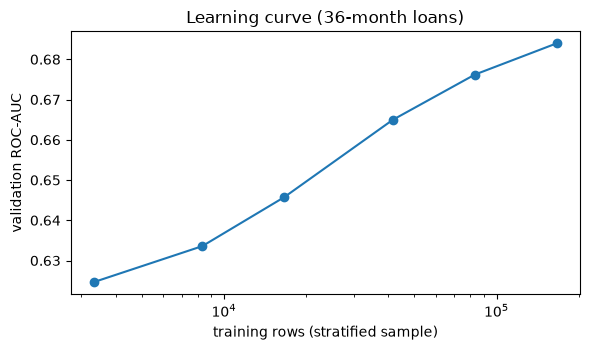

In [5]:
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
import lightgbm as lgb
def strat_sample(d, frac, seed=SEED, by=("term", "year", "y")):
    return d.groupby(list(by), group_keys=False).sample(frac=frac, random_state=seed) if frac < 1 else d
QUICK_NUM = [c for c in CORE_NUM if c not in ("int_rate", "installment")]
QUICK_CAT = ["term", "emp_length", "home_ownership", "verification_status", "purpose", "initial_list_status"]
def quick_X(d, cats=None):
    X = d[QUICK_NUM].astype("float32").copy()
    for c in QUICK_CAT: X[c] = d[c].astype("category").cat.codes
    return X
tr36 = core[(core.term == "36 months") & (core.part == "train")]; va36 = strat_sample(core[(core.term == "36 months") & (core.part == "val")], 0.25)
Xv = quick_X(va36); lc_rows = []
for frac in (0.02, 0.05, 0.10, 0.25, 0.50, 1.0):
    s_ = strat_sample(tr36, frac)
    m = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=50, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, n_jobs=4, verbose=-1)
    m.fit(quick_X(s_), s_.y)
    lc_rows.append({"fraction of train population": frac, "train rows": len(s_), "val ROC-AUC": roc_auc_score(va36.y, m.predict_proba(Xv)[:, 1])})
lc = pd.DataFrame(lc_rows); display(lc.round(4)); lc.round(4).to_csv(ART / "learning_curve.csv", index=False)
fig, ax = plt.subplots(figsize=(6, 3.6)); ax.semilogx(lc["train rows"], lc["val ROC-AUC"], "o-"); ax.set_xlabel("training rows (stratified sample)"); ax.set_ylabel("validation ROC-AUC")
ax.set_title("Learning curve (36-month loans)"); plt.tight_layout(); plt.savefig(FIG / "S_learning_curve.png", dpi=110); plt.show()

## S.4 The sample, its size, and the imbalance decision

In [6]:
F_TRAIN = float(lc.loc[(lc["val ROC-AUC"].max() - lc["val ROC-AUC"]) <= 0.002, "fraction of train population"].min())   # smallest fraction within 0.002 AUC of the best
F_EVAL = 0.25
print("chosen training fraction:", F_TRAIN, "(smallest fraction within 0.002 AUC of the best); validation fraction:", F_EVAL, "(stratified by term, issue year and outcome, so every loan in a stratum has inclusion probability 0.25 and the default rate is preserved; validation is development data); out-of-time test: the FULL population, not sampled; 60-month loans: all rows")
parts = []
for (t, p), d in core.groupby(["term", "part"]):
    if t == "60 months" or p == "test": f = 1.0
    elif p == "train": f = F_TRAIN
    else: f = F_EVAL
    parts.append(strat_sample(d, f))
sample = pd.concat(parts).sort_values("issue", kind="mergesort").reset_index(drop=True)
samp_tab = sample.groupby(["term", "part"]).agg(sample_rows=("y", "size")).join(core.groupby(["term", "part"]).size().rename("population_rows")).reset_index()
samp_tab["fraction"] = (samp_tab.sample_rows / samp_tab.population_rows).round(3)
samp_tab["default_rate"] = [round(sample.y[(sample.term == t) & (sample.part == p)].mean(), 4) if p != "test" else "held out" for t, p in zip(samp_tab.term, samp_tab.part)]
display(samp_tab); samp_tab.to_csv(ART / "sample_summary.csv", index=False)
print("total sample rows:", len(sample), "of", len(core))
print("Imbalance: the 36-month training default rate is", round(sample.y[(sample.term == '36 months') & (sample.part == 'train')].mean(), 3),
      "(mild). No oversampling is used, so no probability correction is needed. A class-weight check is in the Model stage.")

chosen training fraction: 1.0 (smallest fraction within 0.002 AUC of the best); validation fraction: 0.25 (stratified by term, issue year and outcome, so every loan in a stratum has inclusion probability 0.25 and the default rate is preserved; validation is development data); out-of-time test: the FULL population, not sampled; 60-month loans: all rows


,term,part,sample_rows,population_rows,fraction,default_rate
0,36 months,test,282787,282787,1.00,held out
1,36 months,train,166459,166459,1.00,0.1239
2,36 months,val,40643,162570,0.25,0.1373
3,60 months,test,34382,34382,1.00,held out
4,60 months,train,10690,10690,1.00,0.2285
5,60 months,val,9897,9897,1.00,0.277


total sample rows: 544858 of 666785
Imbalance: the 36-month training default rate is 0.124 (mild). No oversampling is used, so no probability correction is needed. A class-weight check is in the Model stage.


## S.5 Is the sample representative? (KS, PSI, chi-square against the population)
Per partition and term, each numeric column is compared with the full eligible population (KS statistic and PSI), and each categorical column with a chi-square test. With hundreds of thousands of rows a p-value is always tiny, so effect sizes (KS, PSI, Cramer's V) are what matter.

In [7]:
from scipy import stats
def psi_num(a, b, bins=10):
    a, b = a.dropna(), b.dropna()
    edges = np.unique(np.quantile(a, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    pa, pb = np.histogram(a, edges)[0] / len(a), np.histogram(b, edges)[0] / len(b)
    pa, pb = np.clip(pa, 1e-4, None), np.clip(pb, 1e-4, None); return float(((pb - pa) * np.log(pb / pa)).sum())
rep = []
for (t, p), d in core.groupby(["term", "part"]):
    s_ = sample[(sample.term == t) & (sample.part == p)]
    if len(s_) == len(d): continue
    ks = {c: stats.ks_2samp(d[c].dropna(), s_[c].dropna()).statistic for c in CORE_NUM if d[c].notna().sum() > 100}
    n_num = len(ks); skipped = [c for c in CORE_NUM if c not in ks]
    ps = {c: psi_num(d[c], s_[c]) for c in ks}
    chi, chi_rows = {}, []
    for c in ["grade", "purpose", "home_ownership", "verification_status", "emp_length", "addr_state"]:
        ct = pd.DataFrame({"pop": d[c].value_counts(), "samp": s_[c].value_counts()}).fillna(0).to_numpy(dtype=float)
        chi2, pv, *_ = stats.chi2_contingency(ct); chi[c] = np.sqrt(chi2 / ct.sum()); chi_rows.append({"column": c, "categories": int(len(ct)), "chi2": chi2, "p_value": pv, "cramers_v": chi[c]})
    bycol = pd.DataFrame({"ks": ks, "psi": ps, "pop_missing": {c: d[c].isna().mean() for c in ks}, "sample_missing": {c: s_[c].isna().mean() for c in ks}})
    bycol.round(5).to_csv(ART / f"sample_representativeness_numeric_{t[:2]}m_{p}.csv"); pd.DataFrame(chi_rows).round(5).to_csv(ART / f"sample_representativeness_categorical_{t[:2]}m_{p}.csv", index=False)
    print(t, p, "| numeric columns tested:", n_num, "| not testable (too few non-missing):", skipped, "| inclusion probability:", round(len(s_) / len(d), 3))
    yr_ks = {int(y_): max(stats.ks_2samp(d.loc[d.year == y_, c].dropna(), s_.loc[s_.year == y_, c].dropna()).statistic for c in ["loan_amnt", "annual_inc", "dti", "fico_range_low", "revol_util"]) for y_ in d.year.unique()}
    print("   max KS on five key columns by issue year:", {k: round(v, 4) for k, v in yr_ks.items()})
    rep.append({"term": t, "part": p, "max KS": max(ks.values()), "worst KS column": max(ks, key=ks.get), "max PSI": max(ps.values()),
                "max Cramers V (categorical)": max(chi.values()), "worst categorical": max(chi, key=chi.get)})
rep = pd.DataFrame(rep); display(rep.round(4)); rep.round(4).to_csv(ART / "sample_representativeness.csv", index=False)
print("rule of thumb: KS below 0.01 and PSI below 0.001 indicate a sample that cannot be told apart from the population. The test is the full population, so it needs no check.")

36 months val | numeric columns tested: 59 | not testable (too few non-missing): [] | inclusion probability: 0.25
   max KS on five key columns by issue year: {2014: np.float64(0.005)}


,term,part,max KS,worst KS column,max PSI,max Cramers V (categorical),worst categorical
0,36 months,val,0.0082,mths_since_recent_bc_dlq,0.0007,0.0114,addr_state


rule of thumb: KS below 0.01 and PSI below 0.001 indicate a sample that cannot be told apart from the population. The test is the full population, so it needs no check.


## S.6 The partitioned datasets used from here on

In [8]:
main = sample[sample.term == "36 months"].reset_index(drop=True)
side60 = sample[sample.term == "60 months"].reset_index(drop=True)
print({p: int((main.part == p).sum()) for p in ("train", "val", "test")}, "| 60-month:", {p: int((side60.part == p).sum()) for p in ("train", "val", "test")})
assert main.issue[main.part == "train"].max() < main.issue[main.part == "val"].min() and main.issue[main.part == "val"].max() < main.issue[main.part == "test"].min()
json.dump({"F_TRAIN": F_TRAIN, "F_EVAL": F_EVAL, "sample_rows": len(sample), "population_rows": len(core), "funnel": F}, open(ART / "metrics_sample.json", "w"), indent=1)

{'train': 166459, 'val': 40643, 'test': 282787} | 60-month: {'train': 10690, 'val': 9897, 'test': 34382}


# E: Explore
**The out-of-time test stays held out.** Every analysis below uses the 36-month **training and validation** partitions only. The shared module `lc_features.py` provides the feature and WoE helpers.

In [9]:
import importlib, lc_features as lf
importlib.reload(lf)
dev = main[main.part != "test"].copy(); tr = main[main.part == "train"].copy(); va = main[main.part == "val"].copy()
dev = lf.add_features(dev); tr = dev[dev.part == "train"]; va = dev[dev.part == "val"]
print("development rows:", len(dev), "| train", len(tr), "| validation", len(va), "| train default rate", round(tr.y.mean(), 4))

development rows: 207102 | train 166459 | validation 40643 | train default rate 0.1239


## E.1 Univariate distributions, missingness, outliers

,count,mean,std,min,1%,50%,99%,max,missing_share
loan_amnt,166459.0,11990.71,7241.48,1000.00,1500.00,10000.00,35000.00,35000.00,0.0000
int_rate,166459.0,12.82,3.93,5.42,6.03,12.99,21.98,25.89,0.0000
annual_inc,166459.0,69475.04,55000.83,4080.00,17508.70,60000.00,226003.36,7141778.00,0.0000
dti,166459.0,16.23,7.60,0.00,1.35,15.89,33.40,34.99,0.0000
fico,166459.0,701.36,31.82,662.00,662.00,692.00,802.00,847.50,0.0000
revol_util,166337.0,56.26,24.12,0.00,0.90,58.30,97.30,140.40,0.0007
credit_hist_years,166459.0,15.03,7.13,3.00,4.00,13.67,37.67,65.41,0.0000
open_acc,166459.0,10.58,4.58,0.00,3.00,10.00,24.00,62.00,0.0000
revol_bal,166459.0,14849.23,18741.06,0.00,113.00,10999.00,73905.14,2568995.00,0.0000
inq_last_6mths,166459.0,0.78,1.01,0.00,0.00,0.00,4.00,8.00,0.0000


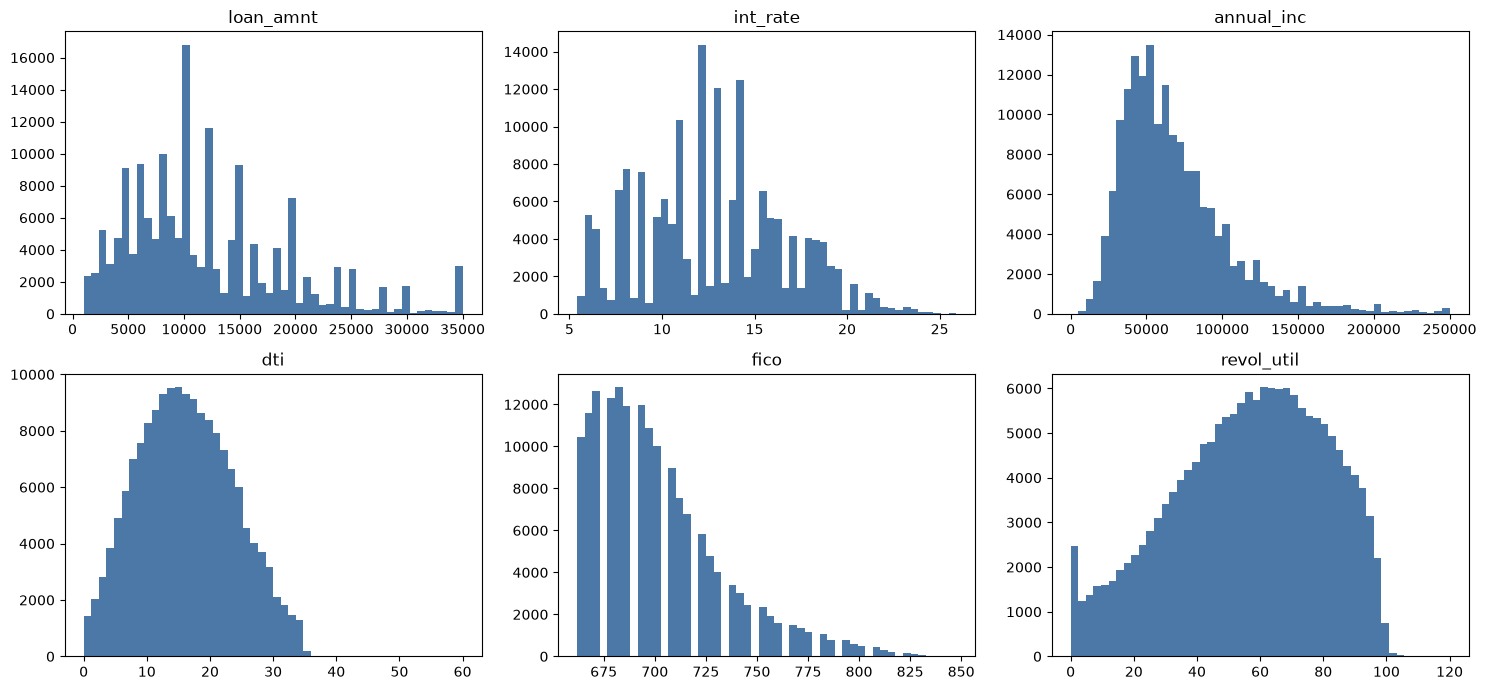

outlier counts in train: {'annual_inc > 500k': 146, 'dti > 60': 0, 'dti < 0': 0, 'revol_util > 100': 171, 'credit history < 0 years': 0, 'fico < 600': 0}


In [10]:
num_show = ["loan_amnt", "int_rate", "annual_inc", "dti", "fico", "revol_util", "credit_hist_years", "open_acc", "revol_bal", "inq_last_6mths"]
desc = tr[num_show].describe(percentiles=[.01, .5, .99]).T[["count", "mean", "std", "min", "1%", "50%", "99%", "max"]].round(2)
desc["missing_share"] = (1 - desc["count"] / len(tr)).round(4); display(desc)
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for a, c, kw in zip(ax.ravel(), ["loan_amnt", "int_rate", "annual_inc", "dti", "fico", "revol_util"], [{}, {}, {"range": (0, 250000)}, {"range": (0, 60)}, {}, {"range": (0, 120)}]):
    a.hist(tr[c].dropna(), bins=50, color="#4C78A8", **kw); a.set_title(c)
plt.tight_layout(); plt.savefig(FIG / "E_distributions.png", dpi=105); plt.show()
out = {"annual_inc > 500k": int((tr.annual_inc > 500000).sum()), "dti > 60": int((tr.dti > 60).sum()), "dti < 0": int((tr.dti < 0).sum()),
       "revol_util > 100": int((tr.revol_util > 100).sum()), "credit history < 0 years": int((tr.credit_hist_years < 0).sum()), "fico < 600": int((tr.fico < 600).sum())}
print("outlier counts in train:", out)

**Missingness patterns.** Many bureau fields were only added to the application later, so their coverage differs by issue year. A model must not learn "this field is present" as a proxy for the calendar year.

In [11]:
cov = dev.groupby("year")[CORE_NUM].agg(lambda s: s.notna().mean()).T.round(2)
cov["train_cov"] = tr[CORE_NUM].notna().mean().round(2)
low = cov[(cov["train_cov"] < 0.95)].sort_values("train_cov")
display(low.head(40)); cov.to_csv(ART / "coverage_by_vintage.csv")
print("columns with train coverage below 95%:", len(low), "of", len(CORE_NUM), "| below 60%:", int((cov.train_cov < 0.6).sum()))

year,2010,2011,2012,2013,2014,train_cov
mths_since_last_record,0.05,0.05,0.03,0.13,0.19,0.09
mths_since_last_major_derog,0.00,0.00,0.10,0.20,0.30,0.15
mths_since_recent_bc_dlq,0.00,0.00,0.13,0.22,0.27,0.17
mths_since_recent_revol_delinq,0.00,0.00,0.26,0.30,0.36,0.25
mths_since_last_delinq,0.35,0.34,0.41,0.44,0.51,0.42
mo_sin_old_il_acct,0.00,0.00,0.46,0.96,0.96,0.70
num_tl_op_past_12m,0.00,0.00,0.48,1.00,1.00,0.73
num_tl_90g_dpd_24m,0.00,0.00,0.48,1.00,1.00,0.73
num_tl_30dpd,0.00,0.00,0.48,1.00,1.00,0.73
num_tl_120dpd_2m,0.00,0.00,0.48,1.00,0.96,0.73


columns with train coverage below 95%: 39 of 59 | below 60%: 5


## E.2 Default rate by grade, purpose, DTI, income, vintage


grade
       loans  default_rate
grade                     
A      44741        0.0558
B      77986        0.1055
C      49571        0.1614
D      27081        0.2065
E       6278        0.2365
F       1336        0.2740
G        109        0.3028

purpose
                     loans  default_rate
purpose                                 
car                   2789        0.0929
major_purchase        5119        0.1000
credit_card          48601        0.1079
home_improvement     11509        0.1080
wedding               1711        0.1105
house                 1129        0.1302
debt_consolidation  115946        0.1312
educational             86        0.1395
vacation              1427        0.1430
other                11405        0.1572
medical               2236        0.1583
moving                1609        0.1672
renewable_energy       203        0.1872
small_business        3332        0.2167

dti_band
          loans  default_rate
dti                          
(-1, 10]  46045

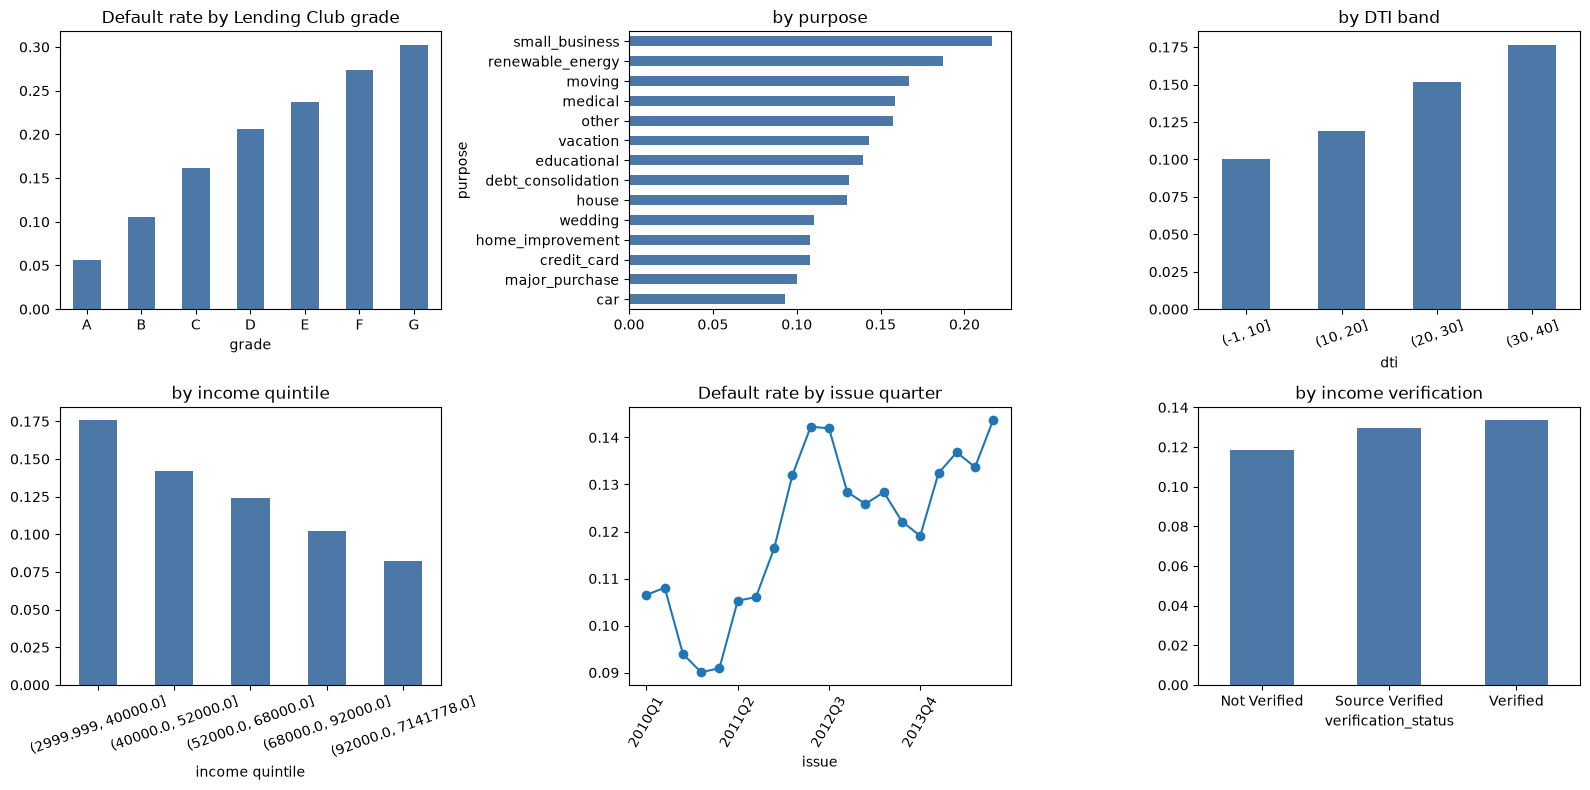

In [12]:
def rate_by(d, key, name=None):
    g = d.groupby(key, observed=True).y.agg(["size", "mean"]).rename(columns={"size": "loans", "mean": "default_rate"}); g.index.name = name or key; return g
tabs = {"grade": rate_by(dev, "grade"), "purpose": rate_by(dev, "purpose").sort_values("default_rate"),
        "dti_band": rate_by(dev, pd.cut(dev.dti, [-1, 10, 20, 30, 40, 1000]), "dti"), "income_band": rate_by(dev, pd.qcut(dev.annual_inc, 5), "income quintile"),
        "year": rate_by(dev, "year"), "verification": rate_by(dev, "verification_status"), "home_ownership": rate_by(dev, "home_ownership")}
for k, v in tabs.items(): print("\n" + k); print(v.round(4))
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
tabs["grade"].default_rate.plot.bar(ax=ax[0, 0], color="#4C78A8", rot=0, title="Default rate by Lending Club grade")
tabs["purpose"].default_rate.plot.barh(ax=ax[0, 1], color="#4C78A8", title="by purpose")
tabs["dti_band"].default_rate.plot.bar(ax=ax[0, 2], color="#4C78A8", rot=20, title="by DTI band")
tabs["income_band"].default_rate.plot.bar(ax=ax[1, 0], color="#4C78A8", rot=20, title="by income quintile")
mon = dev.groupby(dev.issue.dt.to_period("Q").astype(str)).y.mean(); mon.plot(ax=ax[1, 1], marker="o", rot=60, title="Default rate by issue quarter")
tabs["verification"].default_rate.plot.bar(ax=ax[1, 2], color="#4C78A8", rot=0, title="by income verification")
plt.tight_layout(); plt.savefig(FIG / "E_default_rates.png", dpi=105); plt.show()

## E.3 Association screening: information value, correlation
Information value (IV) of each candidate origination variable on the **training** rows (10 quantile bins plus a missing bin). Rules of thumb: below 0.02 useless, 0.02-0.1 weak, 0.1-0.3 medium, 0.3-0.5 strong, above 0.5 suspicious (often leakage).

In [13]:
ENG_NUM = ["credit_hist_years", "fico", "log_income", "log_loan_amnt", "loan_to_income", "emp_length_yrs", "revol_bal_to_income"]
cand_num = [c for c in CORE_NUM if c not in ("fico_range_low", "fico_range_high") and cov.loc[c, "train_cov"] >= 0.05] + ENG_NUM
cand_cat = ["grade", "sub_grade", "home_ownership", "verification_status", "purpose", "initial_list_status", "addr_state"]
cand_num = list(dict.fromkeys(cand_num))
ivt = lf.iv_table(tr, tr.y, cand_num, cand_cat); ivt["train_coverage"] = ivt.variable.map(lambda v: float(cov.loc[v, "train_cov"]) if v in cov.index else 1.0)
display(ivt.head(30).round(4)); ivt.round(4).to_csv(ART / "information_value.csv", index=False)
print("IV above 0.5 (suspicious):", ivt.variable[ivt.iv > 0.5].tolist(), "| IV below 0.02:", int((ivt.iv < 0.02).sum()), "of", len(ivt))
numcorr = tr[[c for c in cand_num if tr[c].notna().mean() > 0.9]].corr(method="spearman")
pairs = numcorr.where(np.triu(np.ones(numcorr.shape), 1).astype(bool)).stack().loc[lambda s: s.abs() > 0.8].sort_values(key=abs, ascending=False)
print("\nvery correlated pairs (|Spearman| > 0.8):"); print(pairs.round(3).head(15))

,variable,iv,strength,train_coverage
0,sub_grade,0.2590,medium,1.00
1,int_rate,0.2506,medium,1.00
2,grade,0.2288,medium,1.00
3,fico,0.1428,medium,1.00
4,annual_inc,0.0949,weak,1.00
5,log_income,0.0949,weak,1.00
6,bc_open_to_buy,0.0695,weak,0.82
7,total_bc_limit,0.0604,weak,0.83
8,tot_hi_cred_lim,0.0560,weak,0.73
9,avg_cur_bal,0.0502,weak,0.73


IV above 0.5 (suspicious): [] | IV below 0.02: 43 of 71



very correlated pairs (|Spearman| > 0.8):
loan_amnt    log_loan_amnt           1.000
annual_inc   log_income              1.000
loan_amnt    installment             0.994
installment  log_loan_amnt           0.994
pub_rec      pub_rec_bankruptcies    0.934
dtype: float64


In [14]:
# categorical association: Cramer's V among the categorical candidates, and each one against the outcome (training loans)
def cramers_v(a, b):
    ct = pd.crosstab(a.astype("object").fillna("MISSING"), b.astype("object").fillna("MISSING")).to_numpy(dtype=float)
    chi2 = stats.chi2_contingency(ct)[0]; n = ct.sum(); k = min(ct.shape) - 1
    return float(np.sqrt(chi2 / (n * k))) if k > 0 else 0.0
from scipy import stats
cats = ["grade", "home_ownership", "purpose", "verification_status", "initial_list_status", "addr_state"]
cv = pd.DataFrame({a: {b: cramers_v(tr[a], tr[b]) for b in cats} for a in cats}).round(3); display(cv); cv.to_csv(ART / "categorical_association.csv")
print("Cramer's V of each categorical vs default:", {c: round(cramers_v(tr[c], tr.y), 3) for c in cats})

,grade,home_ownership,purpose,verification_status,initial_list_status,addr_state
grade,1.000,0.086,0.110,0.054,0.017,0.027
home_ownership,0.086,1.000,0.097,0.086,0.034,0.139
purpose,0.110,0.097,1.000,0.075,0.073,0.030
verification_status,0.054,0.086,0.075,1.000,0.039,0.037
initial_list_status,0.017,0.034,0.073,0.039,1.000,0.038
addr_state,0.027,0.139,0.030,0.037,0.038,1.000


Cramer's V of each categorical vs default: {'grade': 0.154, 'home_ownership': 0.058, 'purpose': 0.06, 'verification_status': 0.013, 'initial_list_status': 0.007, 'addr_state': 0.042}


## E.4 Cluster borrowers

silhouette by k: {2: 0.132, 3: 0.124, 4: 0.143, 5: 0.113, 6: 0.116, 7: 0.116, 8: 0.118}


,loans,default_train,income,dti,fico,revol_util,loan_amnt,hist_years,open_acc,default_val
cluster,,,,,,,,,,
0,13884,0.124,75000.00,14.58,682.0,58.0,10800.0,16.329,11.0,0.1388
1,61717,0.150,45000.00,15.63,687.0,67.8,8500.0,10.836,8.0,0.1646
2,47268,0.122,74475.25,20.32,697.0,62.9,15000.0,16.668,14.0,0.1283
3,14644,0.131,55000.00,14.56,677.0,54.8,9500.0,15.001,9.0,0.1504
4,28946,0.068,67000.00,10.20,747.0,24.2,10000.0,13.834,9.0,0.0728


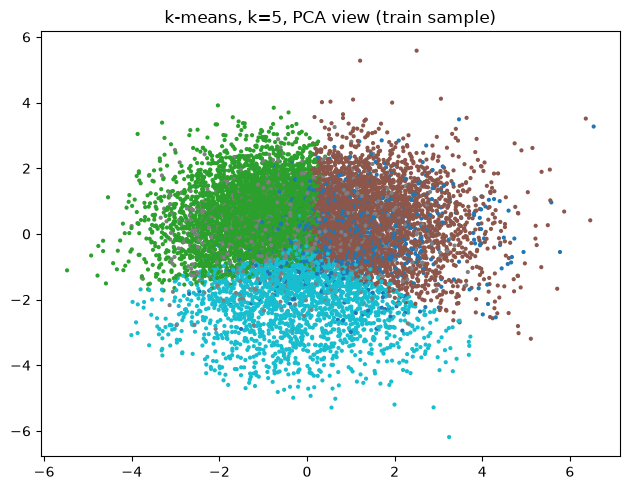

In [15]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
CL = ["log_income", "dti", "fico", "revol_util", "log_loan_amnt", "credit_hist_years", "open_acc", "total_acc", "inq_last_6mths", "delinq_2yrs", "pub_rec", "revol_bal_to_income"]
def cl_prep(d, fit=None):
    X = d[CL].copy(); X["dti"] = X.dti.clip(0, 60); X["revol_util"] = X.revol_util.clip(0, 120); X["revol_bal_to_income"] = X.revol_bal_to_income.clip(0, 2)
    for c in ["open_acc", "total_acc", "inq_last_6mths", "delinq_2yrs", "pub_rec"]: X[c] = X[c].clip(upper=X[c].quantile(.995) if fit is None else fit[c])
    return X
cap_ref = tr[["open_acc", "total_acc", "inq_last_6mths", "delinq_2yrs", "pub_rec"]].quantile(.995)
imp, scl = SimpleImputer(strategy="median").fit(cl_prep(tr, cap_ref)), None
Z = imp.transform(cl_prep(tr, cap_ref)); scl = StandardScaler().fit(Z); Z = scl.transform(Z)
rs = np.random.RandomState(SEED); samp = rs.choice(len(Z), 12000, replace=False)
sil = {k: round(silhouette_score(Z[samp], KMeans(k, n_init=3, random_state=SEED).fit_predict(Z[samp])), 3) for k in range(2, 9)}
print("silhouette by k:", sil)
K = 5; km = KMeans(K, n_init=10, random_state=SEED).fit(Z)
tr = tr.assign(cluster=km.labels_)
va = va.assign(cluster=km.predict(scl.transform(imp.transform(cl_prep(va, cap_ref)))))
prof = tr.groupby("cluster").agg(loans=("y", "size"), default_train=("y", "mean"), income=("annual_inc", "median"), dti=("dti", "median"), fico=("fico", "median"),
                                 revol_util=("revol_util", "median"), loan_amnt=("loan_amnt", "median"), hist_years=("credit_hist_years", "median"), open_acc=("open_acc", "median")).round(3)
prof["default_val"] = va.groupby("cluster").y.mean().round(4); display(prof); prof.to_csv(ART / "clusters_profile.csv")
P2 = PCA(2, random_state=SEED).fit(Z[samp]).transform(Z[samp])
fig, ax = plt.subplots(figsize=(6.4, 5)); ax.scatter(P2[:, 0], P2[:, 1], c=km.labels_[samp], s=4, cmap="tab10"); ax.set_title(f"k-means, k={K}, PCA view (train sample)")
plt.tight_layout(); plt.savefig(FIG / "E_clusters.png", dpi=105); plt.show()

## E.5 What each finding means for Modify
The notebook prints the evidence above. The written log is in `phase_notes/02_explore.md`.

# M: Modify
## M.1 Leakage audit of **every column** (all 151)
Each column is classified as known or not known at origination, with the reason, the share missing in the eligible population, its coverage by era, and, for post-origination columns, how strongly the column alone predicts the outcome on development vintages.

In [16]:
header = list(pd.read_csv(cache["colstats"], index_col=0).index); colmiss = pd.read_csv(cache["colstats"], index_col=0).iloc[:, 0]
leak = pd.read_csv(cache["leak"]).set_index("column")
POST = {"funded_amnt_inv": "set at funding, after the listing", "out_prncp": "balance after origination", "out_prncp_inv": "balance after origination",
        "total_pymnt": "payments received (the outcome)", "total_pymnt_inv": "payments received (the outcome)", "total_rec_prncp": "principal repaid (the outcome)",
        "total_rec_int": "interest paid (the outcome)", "total_rec_late_fee": "late fees (the outcome)", "recoveries": "recoveries after charge-off (the outcome)",
        "collection_recovery_fee": "fees after charge-off (the outcome)", "last_pymnt_d": "last payment date", "last_pymnt_amnt": "last payment amount", "next_pymnt_d": "next payment date",
        "last_credit_pull_d": "credit pulled after origination", "last_fico_range_high": "FICO refreshed after origination", "last_fico_range_low": "FICO refreshed after origination",
        "pymnt_plan": "payment plan set after origination", "funded_amnt": "used only to compute realized profit in Assess", "disbursement_method": "set at funding",
        "debt_settlement_flag": "settlement after distress", "debt_settlement_flag_date": "settlement after distress"}
for c in header:
    if c.startswith(("hardship_", "settlement_")) or c in ("deferral_term", "payment_plan_start_date", "orig_projected_additional_accrued_interest"):
        POST[c] = "hardship or settlement program, after origination"
IDENT = {"id": "identifier", "member_id": "identifier", "url": "identifier"}
TEXT = {"emp_title": "free text, very high cardinality", "desc": "free text, mostly empty after 2013", "title": "free text"}
LCA = {"grade": "Lending Club's own risk grade", "sub_grade": "Lending Club's own risk grade", "int_rate": "rate set by Lending Club's model", "installment": "function of amount, rate and term"}
FAIR = {"zip_code": "proxy for protected groups: kept out of the model, used for fairness review only", "addr_state": "proxy for protected groups: kept out of the model, used for fairness review only"}
JOINT = {c: "joint-application field; joint loans were removed" for c in header if c.startswith("sec_app_") or c in ("annual_inc_joint", "dti_joint", "verification_status_joint", "revol_bal_joint")}
META = {"loan_status": "the target", "issue_d": "used to partition by date; not a feature", "policy_code": "constant", "application_type": "constant after filtering"}
EXPANDED = ["open_acc_6m", "open_act_il", "open_il_12m", "open_il_24m", "mths_since_rcnt_il", "total_bal_il", "il_util", "open_rv_12m", "open_rv_24m", "max_bal_bc", "all_util", "inq_fi", "total_cu_tl", "inq_last_12m"]
era = dev[dev.year >= 2013]
rows = []
for c in header:
    if c in IDENT: cat, why = "identifier", IDENT[c]
    elif c in META: cat, why = "meta", META[c]
    elif c in POST: cat, why = "NOT known at origination", POST[c]
    elif c in TEXT: cat, why = "text", TEXT[c]
    elif c in JOINT: cat, why = "joint", JOINT[c]
    elif c in LCA: cat, why = "Lending Club assessment", LCA[c]
    elif c in FAIR: cat, why = "fairness proxy", FAIR[c]
    elif c in EXPANDED: cat, why = "known at origination", "field introduced around 2015, absent in the training vintages"
    elif c in CORE_NUM or c in CORE_STR or c in ("loan_amnt", "term"): cat, why = "known at origination", "application or credit-bureau field at origination"
    else: cat, why = "UNCLASSIFIED", ""
    rows.append({"column": c, "classification": cat, "reason": why, "missing_share_all_eligible": round(float(colmiss.get(c, np.nan)), 3),
                 "train_coverage": round(float(tr[c].notna().mean()), 3) if c in tr.columns else np.nan,
                 "coverage_2013_on": round(float(era[c].notna().mean()), 3) if c in era.columns else np.nan,
                 "single_column_auc": round(float(leak.single_column_auc.get(c, np.nan)), 3)})
audit = pd.DataFrame(rows)
assert (audit.classification != "UNCLASSIFIED").all(), audit[audit.classification == "UNCLASSIFIED"].column.tolist()
print("columns audited:", len(audit), "| by class:", audit.classification.value_counts().to_dict())
display(audit[audit.classification == "NOT known at origination"].sort_values("single_column_auc", key=lambda s: (s - 0.5).abs(), ascending=False)[["column", "reason", "single_column_auc", "missing_share_all_eligible"]].head(12))

columns audited: 151 | by class: {'known at origination': 78, 'NOT known at origination': 41, 'joint': 16, 'Lending Club assessment': 4, 'meta': 4, 'identifier': 3, 'text': 3, 'fairness proxy': 2}


,column,reason,single_column_auc,missing_share_all_eligible
45,recoveries,recoveries after charge-off (the outcome),0.934,0.0
51,last_fico_range_high,FICO refreshed after origination,0.104,0.0
52,last_fico_range_low,FICO refreshed after origination,0.104,0.0
46,collection_recovery_fee,fees after charge-off (the outcome),0.866,0.0
42,total_rec_prncp,principal repaid (the outcome),0.170,0.0
48,last_pymnt_amnt,last payment amount,0.234,0.0
40,total_pymnt,payments received (the outcome),0.274,0.0
41,total_pymnt_inv,payments received (the outcome),0.274,0.0
44,total_rec_late_fee,late fees (the outcome),0.542,0.0
3,funded_amnt,used only to compute realized profit in Assess,0.520,0.0


## M.2 Variable roles, missing values, outliers, transforms
- **Structural missing ("months since last ..."):** missing means "never happened", so it is informative. Only `mths_since_last_delinq` and `mths_since_last_record` exist in all vintages; they get a missing bin (WoE) or a missing indicator (trees).
- **Bureau block** (33 fields such as `tot_cur_bal`, `bc_util`, `num_*`): absent for 2010-2011 and half of 2012, present from 2013. Missingness would act as a calendar proxy, so these fields are only used in the **extended** variant and are compared with the core variant in the Model stage.
- **Outliers:** values are clipped at the 0.1st and 99.9th percentile of the training rows (trees), or binned (WoE).
- **Transforms:** log income, log loan amount, credit history years, loan-to-income, revolving balance to income, FICO midpoint, employment years.

In [17]:
iv = ivt.set_index("variable")
LCA_NUM = ["int_rate", "installment"]   # Lending Club's own assessment: never in the application-only variants
core_num = [c for c in cand_num if c in tr.columns and c not in LCA_NUM and float(tr[c].notna().mean()) >= 0.95]
struct = ["mths_since_last_delinq", "mths_since_last_record"]
block_num = [c for c in cand_num if c in tr.columns and c not in LCA_NUM and float(tr[c].notna().mean()) < 0.95 and float(era[c].notna().mean()) >= 0.9 and c not in struct and c in CORE_NUM]
cat_core = ["home_ownership", "verification_status", "purpose", "initial_list_status"]
def pick(cols, min_iv=0.02, corr_max=0.8):
    cols = [c for c in cols if iv.iv.get(c, 0) >= min_iv]; kept = []
    for c in sorted(cols, key=lambda v: -iv.iv[v]):
        if all(abs(tr[c].corr(tr[k], method="spearman")) <= corr_max for k in kept): kept.append(c)
    return kept
SEL_NUM_CORE = pick(core_num + struct)
SEL_CAT = [c for c in cat_core if iv.iv.get(c, 0) >= 0.02]
SEL_NUM_EXT = SEL_NUM_CORE + [c for c in pick(block_num + SEL_NUM_CORE) if c not in SEL_NUM_CORE]
dropped_iv = [c for c in core_num + struct + block_num if iv.iv.get(c, 0) < 0.02]
print("core numeric kept (IV >= 0.02, redundancy filtered):", SEL_NUM_CORE)
print("categorical kept:", SEL_CAT, "| dropped for IV < 0.02:", [c for c in cat_core if c not in SEL_CAT])
print("bureau-block numeric added in the extended set:", [c for c in SEL_NUM_EXT if c not in SEL_NUM_CORE])
print("candidates dropped for IV < 0.02:", len(dropped_iv))
sets = pd.DataFrame({"variant": ["A-core", "A-extended", "B (A-extended + Lending Club grade and rate)"],
                     "numeric": [len(SEL_NUM_CORE), len(SEL_NUM_EXT), len(SEL_NUM_EXT) + 1], "categorical": [len(SEL_CAT), len(SEL_CAT), len(SEL_CAT) + 2]}); display(sets)
def treatment(r):
    c = r["column"]
    if r["classification"] != "known at origination": return ""
    if c in struct: return "missing = never happened: own bin (WoE) or indicator (trees); failed the IV filter"
    if c in EXPANDED: return "excluded: absent in the training vintages"
    cov = r["train_coverage"]
    if pd.isna(cov): return "categorical or text-coded: missing becomes the MISSING category"
    if cov >= 0.999: return "none needed (complete)"
    if cov >= 0.95: return "own missing bin (WoE) or missing value (trees); rare"
    if c in block_num: return "bureau block: used only in A-extended, missing bin or indicator; missingness proxies the issue year"
    return "dropped: coverage depends on the issue year and the field is not selected"
audit["missing_treatment"] = audit.apply(treatment, axis=1)
print(audit[audit.classification == "known at origination"].missing_treatment.value_counts().to_string())
audit["in_A_core"] = audit.column.isin(SEL_NUM_CORE + SEL_CAT); audit["in_A_extended"] = audit.column.isin(SEL_NUM_EXT + SEL_CAT)
audit["iv"] = audit.column.map(iv.iv).round(4); audit.to_csv(ART / "leakage_audit_all_columns.csv", index=False)
json.dump({"A_core_num": SEL_NUM_CORE, "A_ext_num": SEL_NUM_EXT, "cat": SEL_CAT, "lc_assessment_num": ["int_rate"], "lc_assessment_cat": ["grade", "sub_grade"]}, open(ART / "model_features.json", "w"), indent=1)

core numeric kept (IV >= 0.02, redundancy filtered): ['fico', 'annual_inc', 'loan_to_income', 'dti', 'revol_util', 'inq_last_6mths']
categorical kept: ['home_ownership', 'purpose'] | dropped for IV < 0.02: ['verification_status', 'initial_list_status']
bureau-block numeric added in the extended set: ['bc_open_to_buy', 'total_bc_limit', 'tot_hi_cred_lim', 'acc_open_past_24mths', 'mort_acc', 'percent_bc_gt_75', 'num_tl_op_past_12m', 'mths_since_recent_bc', 'mo_sin_rcnt_tl', 'mo_sin_rcnt_rev_tl_op', 'mo_sin_old_rev_tl_op']
candidates dropped for IV < 0.02: 36


,variant,numeric,categorical
0,A-core,6,2
1,A-extended,17,2
2,B (A-extended + Lending Club grade and rate),18,4


missing_treatment
bureau block: used only in A-extended, missing bin or indicator; missingness proxies the issue year    33
none needed (complete)                                                                                 24
excluded: absent in the training vintages                                                              14
dropped: coverage depends on the issue year and the field is not selected                               4
missing = never happened: own bin (WoE) or indicator (trees); failed the IV filter                      2
own missing bin (WoE) or missing value (trees); rare                                                    1


## M.3 Everything fit on train only: the reusable pipelines
`WoEBinner` (scorecard) and `TreePrep` (trees, boosted) learn bin edges, WoE values, clip bounds and category codes from the training partition only. The checks below confirm it and recompute one number by hand.

In [18]:
Xtr = lf.add_features(tr); ytr = tr.y.values
wb = lf.WoEBinner(SEL_NUM_CORE, SEL_CAT).fit(Xtr, ytr)
v = "fico"; manual_edges = np.unique(np.nanquantile(tr[v], np.linspace(0, 1, 11)[1:-1]))
print("FICO bin edges fit on train:", wb.edges_[v].round(1).tolist(), "| by hand:", manual_edges.round(1).tolist(), "| equal:", np.allclose(wb.edges_[v], manual_edges))
full_edges = np.unique(np.nanquantile(pd.concat([tr, va])[v], np.linspace(0, 1, 11)[1:-1]))
print("edges if validation rows had been used:", full_edges.round(1).tolist(), "(different, so validation did not leak into the fit)")
b = wb.bin_table_[wb.bin_table_.variable == "fico"].sort_values("bin"); display(b.round(4))
# by-hand WoE of the first FICO bin
first = (tr[v] < wb.edges_[v][0])   # the binner puts a value equal to an edge in the next bin
bad, good = ytr[first].sum(), (1 - ytr[first]).sum()
hand = np.log(((good + .5) / ((1 - ytr).sum() + .5)) / ((bad + .5) / (ytr.sum() + .5)))
print("WoE of the lowest FICO bin: pipeline", round(wb.woe_[v][0], 4), "| by hand", round(float(hand), 4))
tp = lf.TreePrep(SEL_NUM_EXT, SEL_CAT).fit(Xtr)
print("tree prep: features", len(tp.get_feature_names_out()), "| missing indicators:", tp.miss_cols_[:6], "...", len(tp.miss_cols_))
assert (main.issue[main.part == "train"].max() < main.issue[main.part == "val"].min())
print("Modify checks passed")

FICO bin edges fit on train: [667.0, 672.0, 682.0, 687.0, 692.0, 702.0, 712.0, 722.0, 747.0] | by hand: [667.0, 672.0, 682.0, 687.0, 692.0, 702.0, 712.0, 722.0, 747.0] | equal: True
edges if validation rows had been used: [667.0, 672.0, 677.0, 687.0, 692.0, 702.0, 712.0, 722.0, 742.0] (different, so validation did not leak into the fit)


,variable,kind,bin,loans,bad_rate,woe,iv_part
9,fico,num,0,10465,0.1846,-0.4709,0.0166
4,fico,num,1,11575,0.1730,-0.3915,0.0123
8,fico,num,2,24958,0.1595,-0.2940,0.0145
7,fico,num,3,12817,0.1497,-0.2195,0.0040
6,fico,num,4,11941,0.1394,-0.1364,0.0014
1,fico,num,5,22833,0.1302,-0.0567,0.0005
2,fico,num,6,19009,0.1115,0.1189,0.0015
3,fico,num,7,14335,0.0964,0.2814,0.0061
0,fico,num,8,21073,0.0818,0.4616,0.0226
5,fico,num,9,17453,0.0531,0.9253,0.0633


WoE of the lowest FICO bin: pipeline -0.4709 | by hand -0.4709
tree prep: features 30 | missing indicators: ['bc_open_to_buy', 'total_bc_limit', 'tot_hi_cred_lim', 'acc_open_past_24mths', 'mort_acc', 'percent_bc_gt_75'] ... 11
Modify checks passed


# M: Model
**The out-of-time test stays held out.** All fitting uses the 36-month training loans, all tuning uses the 2014 validation loans.
## M.1 Candidates
| Family | Variants | Why |
|---|---|---|
| Majority (prior) and FICO-only logistic regression | baselines | floor, and the comparison required by criterion C1 |
| WoE logistic **scorecard** | A-core, A-extended, B | the industry standard: transparent points per bin |
| Decision tree | A-extended | readable rules |
| **LightGBM** (boosted trees) | A-core, A-extended, B | strong tabular learner |
| Neural network (small MLP on WoE inputs) | A-extended | the neural-network candidate from the SEMMA toolset |
**Choice rule, fixed before looking at results:** within each variant family, take the best validation ROC-AUC, but prefer the scorecard if it is within 0.005 AUC of the best (credit-risk practice values transparency).

In SAS the same flow would be Data, Partition, Impute, Regression, Decision Tree, Neural Network and Model Comparison nodes. SAS access was not available for this project (see the report), so only the Python flow is built and a SAS score-code export is generated in the deployment extension.

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.calibration import CalibratedClassifierCV
CAT_B = SEL_CAT + ["grade", "sub_grade"]; NUM_B = SEL_NUM_EXT + ["int_rate"]
FE = {p: lf.add_features(main[main.part == p]) for p in ("train", "val")}
ytr, yva = FE["train"].y.values, FE["val"].y.values
def metrics(y, p): return {"roc_auc": roc_auc_score(y, p), "pr_auc": average_precision_score(y, p), "ks": lf.ks_stat(y, p), "brier": brier_score_loss(y, p)}
res, models = {}, {}
def record(name, model, Xv, extra=None):
    p = model.predict_proba(Xv)[:, 1]; res[name] = {**metrics(yva, p), **(extra or {})}; models[name] = model; return p

## M.2 Baselines

In [20]:
Pipe, TreeModel = lf.Pipe, lf.TreeModel
Xtr_, Xva_ = FE["train"], FE["val"]
record("Majority (prior)", DummyClassifier(strategy="prior").fit(Xtr_[["fico"]], ytr), Xva_[["fico"]])
fico_lr = Pipe(lf.WoEBinner(["fico"], []), LogisticRegression(max_iter=300)).fit(Xtr_, ytr); record("FICO-only logistic (WoE)", fico_lr, Xva_)
display(pd.DataFrame(res).T.round(4))

,roc_auc,pr_auc,ks,brier
Majority (prior),0.5000,0.1373,0.0000,0.1186
FICO-only logistic (WoE),0.5964,0.1714,0.1487,0.1168


## M.3 WoE logistic scorecards (A-core, A-extended, B), tuned on validation

In [21]:
def fit_scorecard(num, cat, name):
    wb = lf.WoEBinner(num, cat).fit(Xtr_, ytr); Ztr, Zva = wb.transform(Xtr_), wb.transform(Xva_); best = None
    for C in (0.01, 0.1, 1.0, 10.0):
        lr = LogisticRegression(C=C, max_iter=500).fit(Ztr, ytr); auc = roc_auc_score(yva, lr.predict_proba(Zva)[:, 1])
        if best is None or auc > best[0]: best = (auc, C, lr)
    m = Pipe(wb, best[2]); m.C = best[1]; record(name, m, Xva_, {"setting": f"C={best[1]}"}); return m
sc_core = fit_scorecard(SEL_NUM_CORE, SEL_CAT, "Scorecard A-core")
sc_ext = fit_scorecard(SEL_NUM_EXT, SEL_CAT, "Scorecard A-extended")
sc_b = fit_scorecard(NUM_B, CAT_B, "Scorecard B")
# class-weight check (imbalance decision from Sample)
cw = LogisticRegression(C=sc_ext.C, max_iter=500, class_weight="balanced").fit(sc_ext.prep.transform(Xtr_), ytr)
pcw = cw.predict_proba(sc_ext.prep.transform(Xva_))[:, 1]
print("class-weight check (A-extended scorecard): ROC-AUC", round(roc_auc_score(yva, pcw), 4), "vs", round(res["Scorecard A-extended"]["roc_auc"], 4),
      "| Brier", round(brier_score_loss(yva, pcw), 4), "vs", round(res["Scorecard A-extended"]["brier"], 4), "-> no gain in ranking, worse probabilities: no reweighting")
display(pd.DataFrame(res).T.round(4))

class-weight check (A-extended scorecard): ROC-AUC 0.6638 vs 0.6641 | Brier 0.246 vs 0.1136 -> no gain in ranking, worse probabilities: no reweighting


,roc_auc,pr_auc,ks,brier,setting
Majority (prior),0.5,0.137268,0.0,0.118605,NaN
FICO-only logistic (WoE),0.596371,0.171413,0.148664,0.116803,NaN
Scorecard A-core,0.648946,0.217017,0.218362,0.114571,C=0.01
Scorecard A-extended,0.664101,0.229349,0.242783,0.113625,C=0.01
Scorecard B,0.68122,0.240603,0.269213,0.112656,C=0.01


## M.4 Decision tree, boosted trees and neural network (tuned on validation)

In [22]:
def tree_X(num, cat):
    tp = lf.TreePrep(num, cat).fit(Xtr_); return tp, tp.transform(Xtr_), tp.transform(Xva_)
tpE, TtrE, TvaE = tree_X(SEL_NUM_EXT, SEL_CAT)
tree_best = None
for d in (4, 6, 8):
    for leaf in (200, 500):
        t = DecisionTreeClassifier(max_depth=d, min_samples_leaf=leaf, random_state=SEED).fit(TtrE, ytr); auc = roc_auc_score(yva, t.predict_proba(TvaE)[:, 1])
        if tree_best is None or auc > tree_best[0]: tree_best = (auc, d, leaf, t)
record("Decision tree A-extended", TreeModel(tpE, tree_best[3]), Xva_, {"setting": f"depth={tree_best[1]}, leaf={tree_best[2]}"})
def fit_lgbm(num, cat, name):
    tp, Ttr, Tva = tree_X(num, cat); best = None
    for nl, mcs in ((15, 100), (31, 100), (31, 300), (63, 300)):
        m = lgb.LGBMClassifier(n_estimators=1000, learning_rate=0.03, num_leaves=nl, min_child_samples=mcs, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                               reg_lambda=5.0, random_state=SEED, n_jobs=4, verbose=-1)
        m.fit(Ttr, ytr, eval_set=[(Tva, yva)], eval_metric="auc", callbacks=[lgb.early_stopping(50, verbose=False)])
        auc = roc_auc_score(yva, m.predict_proba(Tva)[:, 1])
        if best is None or auc > best[0]: best = (auc, nl, mcs, m)
    record(name, TreeModel(tp, best[3]), Xva_, {"setting": f"leaves={best[1]}, min_leaf={best[2]}, trees={best[3].best_iteration_}"}); return models[name]
gb_core = fit_lgbm(SEL_NUM_CORE, SEL_CAT, "LightGBM A-core")
gb_ext = fit_lgbm(SEL_NUM_EXT, SEL_CAT, "LightGBM A-extended")
gb_b = fit_lgbm(NUM_B, CAT_B, "LightGBM B")
Ztr_e, Zva_e = sc_ext.prep.transform(Xtr_), sc_ext.prep.transform(Xva_)
mlp = MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-3, early_stopping=True, validation_fraction=0.1, n_iter_no_change=8, max_iter=80, random_state=SEED).fit(Ztr_e, ytr)
record("Neural net (MLP) A-extended", Pipe(sc_ext.prep, mlp), Xva_, {"setting": "hidden (32, 16), early stopping"})
cmp_tab = pd.DataFrame(res).T; cmp_tab.index.name = "model"; display(cmp_tab.round(4)); cmp_tab.round(4).to_csv(ART / "model_comparison_validation.csv")

,roc_auc,pr_auc,ks,brier,setting
model,,,,,
Majority (prior),0.5,0.137268,0.0,0.118605,NaN
FICO-only logistic (WoE),0.596371,0.171413,0.148664,0.116803,NaN
Scorecard A-core,0.648946,0.217017,0.218362,0.114571,C=0.01
Scorecard A-extended,0.664101,0.229349,0.242783,0.113625,C=0.01
Scorecard B,0.68122,0.240603,0.269213,0.112656,C=0.01
Decision tree A-extended,0.642645,0.210367,0.21274,0.115054,"depth=8, leaf=200"
LightGBM A-core,0.655478,0.222608,0.229801,0.114177,"leaves=15, min_leaf=100, trees=241"
LightGBM A-extended,0.678394,0.241323,0.263644,0.112753,"leaves=31, min_leaf=300, trees=373"
LightGBM B,0.688795,0.250359,0.275535,0.11224,"leaves=31, min_leaf=300, trees=264"


## M.5 Champions (rule fixed above) and the profit cutoff, chosen on validation

In [23]:
def champion(variant_names, scorecard):
    best = max(variant_names, key=lambda n: res[n]["roc_auc"])
    return scorecard if res[scorecard]["roc_auc"] >= res[best]["roc_auc"] - 0.005 else best
CHAMP_A = champion(["Scorecard A-core", "Scorecard A-extended", "Decision tree A-extended", "LightGBM A-core", "LightGBM A-extended", "Neural net (MLP) A-extended"], "Scorecard A-extended")
CHAMP_B = champion(["Scorecard B", "LightGBM B"], "Scorecard B")
print("Model A champion:", CHAMP_A, "| Model B champion:", CHAMP_B)
print({k: round(v["roc_auc"], 4) for k, v in res.items()})
# realized profit per loan on validation: total_pymnt - funded_amnt (outcome columns, used only here and in Assess)
val_profit = (Xva_.total_pymnt - Xva_.funded_amnt).values; val_funded = Xva_.funded_amnt.values
p_champ_val = models[CHAMP_A].predict_proba(Xva_)[:, 1]
order = np.argsort(p_champ_val); cum = np.cumsum(val_profit[order])
cuts = np.arange(0.02, 1.0, 0.01); tot = []
for c in cuts: tot.append(val_profit[p_champ_val <= c].sum())
CUT = float(cuts[int(np.argmax(tot))])
acc = p_champ_val <= CUT
print(f"validation: accept-all profit {val_profit.sum():,.0f} on {val_funded.sum():,.0f} funded ({val_profit.sum() / val_funded.sum():.2%}) | cutoff PD <= {CUT:.2f}: accepts {acc.mean():.1%} of loans, profit {val_profit[acc].sum():,.0f} on {val_funded[acc].sum():,.0f} funded ({val_profit[acc].sum() / val_funded[acc].sum():.2%})")
print("profit rate by PD decile on validation:", pd.Series(val_profit / val_funded).groupby(pd.qcut(p_champ_val, 10, labels=False)).mean().round(3).to_dict())

Model A champion: LightGBM A-extended | Model B champion: LightGBM B
{'Majority (prior)': 0.5, 'FICO-only logistic (WoE)': 0.5964, 'Scorecard A-core': 0.6489, 'Scorecard A-extended': 0.6641, 'Scorecard B': 0.6812, 'Decision tree A-extended': 0.6426, 'LightGBM A-core': 0.6555, 'LightGBM A-extended': 0.6784, 'LightGBM B': 0.6888, 'Neural net (MLP) A-extended': 0.6619}


validation: accept-all profit 46,652,710 on 513,165,375 funded (9.09%) | cutoff PD <= 0.38: accepts 99.6% of loans, profit 46,720,580 on 511,305,900 funded (9.14%)
profit rate by PD decile on validation: {0: 0.089, 1: 0.1, 2: 0.103, 3: 0.103, 4: 0.104, 5: 0.099, 6: 0.099, 7: 0.086, 8: 0.073, 9: 0.05}


## M.6 Secondary check: 60-month loans, modeled separately

In [24]:
tr60, va60 = lf.add_features(side60[side60.part == "train"]), lf.add_features(side60[side60.part == "val"])
wb60 = lf.WoEBinner(SEL_NUM_CORE, SEL_CAT).fit(tr60, tr60.y.values)
lr60 = LogisticRegression(C=1.0, max_iter=500).fit(wb60.transform(tr60), tr60.y.values)
p60 = lr60.predict_proba(wb60.transform(va60))[:, 1]
print("60-month scorecard (A-core), trained 2010-2011 on", len(tr60), "loans, validation 2012:", len(va60), "| ROC-AUC", round(roc_auc_score(va60.y, p60), 4), "| KS", round(lf.ks_stat(va60.y.values, p60), 4))

60-month scorecard (A-core), trained 2010-2011 on 10690 loans, validation 2012: 9897 | ROC-AUC 0.629 | KS 0.1814


## M.7 Freeze everything before the test is opened

In [25]:
FROZEN = {"A-core scorecard": sc_core, "A-extended scorecard": sc_ext, "B scorecard": sc_b, "FICO-only": fico_lr, "Decision tree A-extended": models["Decision tree A-extended"],
          "LightGBM A-core": gb_core, "LightGBM A-extended": gb_ext, "LightGBM B": gb_b, "MLP A-extended": models["Neural net (MLP) A-extended"], "60-month scorecard": (wb60, lr60)}
import joblib
(ART / "frozen").mkdir(exist_ok=True)
joblib.dump(FROZEN, ART / "frozen" / "candidates.joblib", compress=3)
frozen = {"frozen_at_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"), "test_opened": False, "champion_A": CHAMP_A, "champion_B": CHAMP_B,
          "cutoff_pd": CUT, "validation": {k: {a: (b if isinstance(b, str) else float(b)) for a, b in v.items()} for k, v in res.items()},
          "candidates_sha256": hashlib.sha256((ART / "frozen" / "candidates.joblib").read_bytes()).hexdigest()[:16],
          "features": {"A_core_num": SEL_NUM_CORE, "A_ext_num": SEL_NUM_EXT, "cat": SEL_CAT}, "seed": SEED}
json.dump(frozen, open(ART / "frozen_policy.json", "w"), indent=1)
print({k: frozen[k] for k in ("frozen_at_utc", "test_opened", "champion_A", "champion_B", "cutoff_pd", "candidates_sha256")})

{'frozen_at_utc': '2026-11-09T21:09:14+00:00', 'test_opened': False, 'champion_A': 'LightGBM A-extended', 'champion_B': 'LightGBM B', 'cutoff_pd': 0.37999999999999995, 'candidates_sha256': '9fa66f801ba83755'}


# A: Assess
## A.0 Open the out-of-time test (once)
The frozen candidates are loaded from disk, their hash is checked, and the 2015 test loans (the **full** population, 282,787 loans) are scored once. Nothing is changed after this point.

In [26]:
frozen = json.load(open(ART / "frozen_policy.json"))
assert hashlib.sha256((ART / "frozen" / "candidates.joblib").read_bytes()).hexdigest()[:16] == frozen["candidates_sha256"], "frozen candidates changed"
CAND = joblib.load(ART / "frozen" / "candidates.joblib")
te = lf.add_features(main[main.part == "test"]).reset_index(drop=True); yte = te.y.values
SCORES = {}
for name in ("FICO-only", "A-core scorecard", "A-extended scorecard", "Decision tree A-extended", "LightGBM A-core", "LightGBM A-extended", "MLP A-extended", "B scorecard", "LightGBM B"):
    SCORES[name] = CAND[name].predict_proba(te)[:, 1]          # the only scoring call per candidate
json.dump({"test_opened_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds"), "scoring_calls_per_candidate": 1, "test_loans": len(te),
           "candidates_sha256": frozen["candidates_sha256"]}, open(ART / "test_access_log.json", "w"))
profit = (te.total_pymnt - te.funded_amnt).values; funded = te.funded_amnt.values
print("test loans:", len(te), "| observed default rate:", round(yte.mean(), 4), "| accept-all return on funded dollars:", round(profit.sum() / funded.sum(), 4))

test loans: 282787 | observed default rate: 0.1488 | accept-all return on funded dollars: 0.0655


## A.1 Discrimination: ROC-AUC, PR-AUC, KS, Gini on the out-of-time test

In [27]:
def full_metrics(y, p): return {**metrics(y, p), "gini": 2 * roc_auc_score(y, p) - 1}
tab = pd.DataFrame({k: full_metrics(yte, v) for k, v in SCORES.items()}).T
tab["validation_auc"] = [frozen["validation"][m]["roc_auc"] for m in ("Scorecard A-core", "Scorecard A-core", "Scorecard A-extended", "Decision tree A-extended", "LightGBM A-core", "LightGBM A-extended", "Neural net (MLP) A-extended", "Scorecard B", "LightGBM B")]
tab.loc["FICO-only", "validation_auc"] = frozen["validation"]["FICO-only logistic (WoE)"]["roc_auc"]
tab["auc_change"] = tab.roc_auc - tab.validation_auc
display(tab.round(4)); tab.round(4).to_csv(ART / "test_discrimination.csv")
CH = "LightGBM A-extended"; pA = SCORES[CH]
print("Model A champion on the test:", {k: round(v, 4) for k, v in full_metrics(yte, pA).items()})

,roc_auc,pr_auc,ks,brier,gini,validation_auc,auc_change
FICO-only,0.6008,0.1869,0.1519,0.1250,0.2016,0.5964,0.0044
A-core scorecard,0.6456,0.2278,0.2107,0.1231,0.2913,0.6489,-0.0033
A-extended scorecard,0.6664,0.2456,0.2418,0.1215,0.3328,0.6641,0.0023
Decision tree A-extended,0.6400,0.2240,0.2063,0.1233,0.2800,0.6426,-0.0027
LightGBM A-core,0.6516,0.2312,0.2200,0.1227,0.3032,0.6555,-0.0039
LightGBM A-extended,0.6793,0.2567,0.2598,0.1206,0.3586,0.6784,0.0009
MLP A-extended,0.6655,0.2442,0.2385,0.1218,0.3310,0.6619,0.0036
B scorecard,0.6871,0.2618,0.2726,0.1203,0.3743,0.6812,0.0059
LightGBM B,0.6927,0.2696,0.2789,0.1205,0.3854,0.6888,0.0039


Model A champion on the test: {'roc_auc': 0.6793, 'pr_auc': 0.2567, 'ks': 0.2598, 'brier': 0.1206, 'gini': 0.3586}


## A.2 Decile lift table (Model A champion)

In [28]:
dec = pd.qcut(pA, 10, labels=False, duplicates="drop")
lift = pd.DataFrame({"loans": pd.Series(yte).groupby(dec).size(), "mean_pd": pd.Series(pA).groupby(dec).mean(), "default_rate": pd.Series(yte).groupby(dec).mean(),
                     "return_on_funded": pd.Series(profit).groupby(dec).sum() / pd.Series(funded).groupby(dec).sum()})
lift["lift"] = lift.default_rate / yte.mean(); lift["cum_share_of_defaults"] = (pd.Series(yte).groupby(dec).sum()[::-1].cumsum() / yte.sum())[::-1] if False else (pd.Series(yte).groupby(dec).sum().iloc[::-1].cumsum() / yte.sum()).iloc[::-1]
display(lift.round(4)); lift.round(4).to_csv(ART / "test_decile_lift.csv")
print("top decile of risk captures", round(float(lift.cum_share_of_defaults.iloc[-1]), 3), "of defaults; riskiest-decile default rate", round(float(lift.default_rate.iloc[-1]), 3))

,loans,mean_pd,default_rate,return_on_funded,lift,cum_share_of_defaults
0,28279,0.0311,0.0344,0.0759,0.2309,1.0000
1,28279,0.0538,0.0636,0.0822,0.4272,0.9769
2,28278,0.0709,0.0850,0.0805,0.5712,0.9342
3,28279,0.0875,0.1102,0.0760,0.7401,0.8771
4,28279,0.1050,0.1240,0.0791,0.8335,0.8031
5,28278,0.1240,0.1507,0.0719,1.0124,0.7197
6,28279,0.1463,0.1728,0.0650,1.1613,0.6185
7,28278,0.1736,0.2033,0.0545,1.3659,0.5023
8,28279,0.2110,0.2351,0.0449,1.5793,0.3657
9,28279,0.2895,0.3093,0.0125,2.0782,0.2078


top decile of risk captures 0.208 of defaults; riskiest-decile default rate 0.309


## A.3 Calibration (criterion C3)

In [29]:
def cal_fit(y, p):
    q = np.clip(p, 1e-6, 1 - 1e-6); z = np.log(q / (1 - q)).reshape(-1, 1)
    m = LogisticRegression(C=1e9, max_iter=500).fit(z, y); return float(m.coef_[0, 0]), float(m.intercept_[0])
slope, icpt = cal_fit(yte, pA)
print(f"raw: slope {slope:.3f}, intercept {icpt:.3f} | mean predicted {pA.mean():.4f} vs observed {yte.mean():.4f} (gap {100 * (yte.mean() - pA.mean()):.2f} points)")
# Platt recalibration fitted on the 2014 validation loans only, applied to the test
pv_A = CAND[CH].predict_proba(lf.add_features(main[main.part == "val"]))[:, 1]; yv_ = main[main.part == "val"].y.values
qv = np.clip(pv_A, 1e-6, 1 - 1e-6); platt = LogisticRegression(C=1e9, max_iter=500).fit(np.log(qv / (1 - qv)).reshape(-1, 1), yv_)
qt = np.clip(pA, 1e-6, 1 - 1e-6); pA_recal = platt.predict_proba(np.log(qt / (1 - qt)).reshape(-1, 1))[:, 1]
slope_r, icpt_r = cal_fit(yte, pA_recal)
print(f"after Platt recalibration on 2014: slope {slope_r:.3f}, intercept {icpt_r:.3f} | mean predicted {pA_recal.mean():.4f} | Brier {brier_score_loss(yte, pA_recal):.4f} vs raw {brier_score_loss(yte, pA):.4f}")
rel = pd.DataFrame({"p": pA, "y": yte}).groupby(pd.qcut(pA, 10, duplicates="drop")).agg(mean_pred=("p", "mean"), observed=("y", "mean")); display(rel.round(4))

raw: slope 0.955, intercept 0.094 | mean predicted 0.1293 vs observed 0.1488 (gap 1.96 points)


after Platt recalibration on 2014: slope 0.973, intercept 0.065 | mean predicted 0.1361 | Brier 0.1204 vs raw 0.1206


,mean_pred,observed
"(0.00519, 0.0445]",0.0311,0.0344
"(0.0445, 0.0626]",0.0538,0.0636
"(0.0626, 0.0791]",0.0709,0.0850
"(0.0791, 0.0961]",0.0875,0.1102
"(0.0961, 0.114]",0.1050,0.1240
"(0.114, 0.134]",0.1240,0.1507
"(0.134, 0.159]",0.1463,0.1728
"(0.159, 0.19]",0.1736,0.2033
"(0.19, 0.236]",0.2110,0.2351
"(0.236, 0.609]",0.2895,0.3093


## A.4 Profit under the stated convention (criterion C4)
Policy fixed on validation: accept a loan if the Model A champion's PD is at most the validation cutoff. Value = realized profit of accepted loans (declined loans earn 0). The difference in return per funded dollar between the policy and accepting everything is bootstrapped by **issue month** (12 blocks).

In [30]:
CUT = frozen["cutoff_pd"]; acc = pA <= CUT
months = te.issue.dt.month.values
def ret(a, idx=None):
    m = np.ones(len(a), bool) if idx is None else idx
    return profit[m & a].sum() / funded[m & a].sum()
base_ret, pol_ret = profit.sum() / funded.sum(), ret(acc)
mb = pd.DataFrame({"mo": months, "f_all": funded, "p_all": profit, "f_acc": funded * acc, "p_acc": profit * acc}).groupby("mo").sum()
rng = np.random.RandomState(SEED); idx = rng.randint(0, len(mb), (4000, len(mb))); g = mb.values[idx].sum(1)
diff = g[:, 3] / g[:, 2] - g[:, 1] / g[:, 0]
print(f"cutoff PD <= {CUT:.2f}: accepts {acc.mean():.1%} of loans | return on funded: accept-all {base_ret:.4%}, policy {pol_ret:.4%}, difference {100 * (pol_ret - base_ret):.3f} points | 95% month-block CI of the difference: [{100 * np.percentile(diff, 2.5):.3f}, {100 * np.percentile(diff, 97.5):.3f}] points")
print(f"total profit: accept-all {profit.sum():,.0f} | policy {profit[acc].sum():,.0f}")
# acceptance-share curves for several rankings (read-only comparison)
rows = []
for share in (1.0, 0.9, 0.8, 0.7, 0.5):
    r = {"share accepted": share}
    for nm, sc in {"Model A (LightGBM)": pA, "Model B (LightGBM)": SCORES["LightGBM B"], "FICO-only": SCORES["FICO-only"]}.items():
        a = sc <= np.quantile(sc, share) if share < 1 else np.ones(len(sc), bool)
        r[nm + " return"] = ret(a); r[nm + " total profit (M)"] = profit[a].sum() / 1e6
    rows.append(r)
curve = pd.DataFrame(rows).set_index("share accepted"); display(curve.round(4)); curve.round(4).to_csv(ART / "test_profit_by_acceptance_share.csv")
print("random acceptance of any share earns the accept-all return of", round(base_ret, 4), "in expectation")

cutoff PD <= 0.38: accepts 99.5% of loans | return on funded: accept-all 6.5477%, policy 6.5990%, difference 0.051 points | 95% month-block CI of the difference: [0.042, 0.061] points
total profit: accept-all 237,068,449 | policy 237,704,844


,Model A (LightGBM) return,Model A (LightGBM) total profit (M),Model B (LightGBM) return,Model B (LightGBM) total profit (M),FICO-only return,FICO-only total profit (M)
share accepted,,,,,,
1.0,0.0655,237.0684,0.0655,237.0684,0.0655,237.0684
0.9,0.0709,232.8664,0.0709,232.9725,0.0655,237.0684
0.8,0.0737,218.3250,0.0735,217.8708,0.0676,203.6162
0.7,0.0761,200.6967,0.0751,198.8930,0.0676,203.6162
0.5,0.0787,154.6517,0.0768,152.4670,0.0696,149.6497


random acceptance of any share earns the accept-all return of 0.0655 in expectation


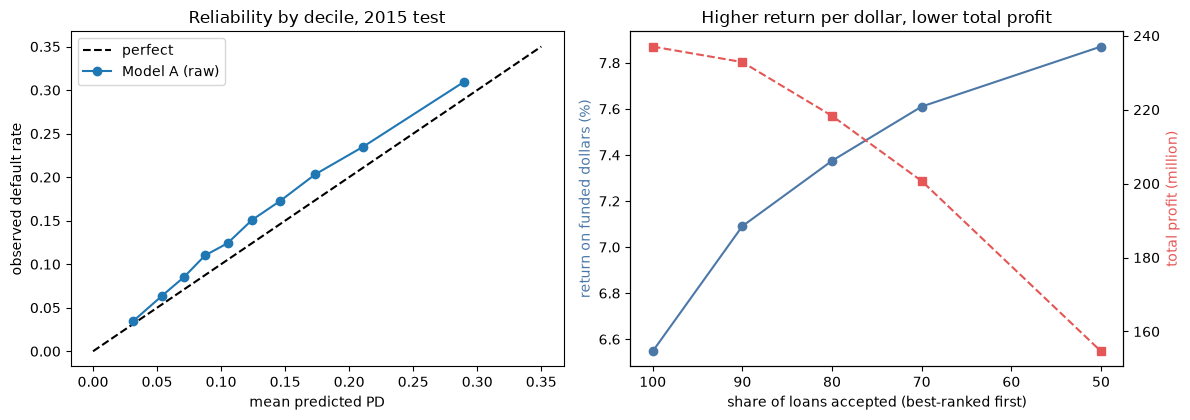

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
ax[0].plot([0, .35], [0, .35], "k--", label="perfect"); ax[0].plot(rel.mean_pred, rel.observed, "o-", label="Model A (raw)"); ax[0].set_xlabel("mean predicted PD"); ax[0].set_ylabel("observed default rate")
ax[0].set_title("Reliability by decile, 2015 test"); ax[0].legend()
ax[1].plot(curve.index * 100, curve["Model A (LightGBM) return"] * 100, "o-", color="#4C78A8"); ax[1].set_xlabel("share of loans accepted (best-ranked first)"); ax[1].set_ylabel("return on funded dollars (%)", color="#4C78A8"); ax[1].invert_xaxis()
a2 = ax[1].twinx(); a2.plot(curve.index * 100, curve["Model A (LightGBM) total profit (M)"], "s--", color="#E45756"); a2.set_ylabel("total profit (million)", color="#E45756"); ax[1].set_title("Higher return per dollar, lower total profit")
plt.tight_layout(); plt.savefig(FIG / "A_calibration_and_profit.png", dpi=110); plt.show()

## A.5 Stability: PSI over vintages and AUC by quarter (criterion C5)

In [32]:
def psi_scores(ref, cur, bins=10):
    e = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1))); e[0], e[-1] = -np.inf, np.inf
    pr, pc = np.histogram(ref, e)[0] / len(ref), np.histogram(cur, e)[0] / len(cur)
    pr, pc = np.clip(pr, 1e-4, None), np.clip(pc, 1e-4, None); return float(((pc - pr) * np.log(pc / pr)).sum())
ptr = CAND[CH].predict_proba(lf.add_features(main[main.part == "train"]))[:, 1]
psi_v, psi_t = psi_scores(ptr, pv_A), psi_scores(ptr, pA)
print(f"score PSI: train to validation {psi_v:.3f}, train to test {psi_t:.3f}")
q = te.issue.dt.quarter.values
stab = pd.DataFrame([{"test quarter": f"2015Q{k}", "loans": int((q == k).sum()), "default_rate": yte[q == k].mean(), "mean_pd": pA[q == k].mean(), "roc_auc": roc_auc_score(yte[q == k], pA[q == k]),
                      "score_psi_vs_train": psi_scores(ptr, pA[q == k])} for k in (1, 2, 3, 4)]); display(stab.round(4)); stab.round(4).to_csv(ART / "test_stability_by_quarter.csv", index=False)
feat_psi = {c: psi_scores(tr[c].dropna().values, te[c].dropna().values) for c in ["fico", "annual_inc", "dti", "loan_amnt", "revol_util", "loan_to_income", "tot_hi_cred_lim", "bc_open_to_buy"] if te[c].notna().mean() > 0.5}
print("feature PSI train to test:", {k: round(v, 3) for k, v in feat_psi.items()})

score PSI: train to validation 0.009, train to test 0.007


,test quarter,loans,default_rate,mean_pd,roc_auc,score_psi_vs_train
0,2015Q1,56568,0.1483,0.1333,0.6732,0.0164
1,2015Q2,64222,0.1538,0.1319,0.6763,0.0123
2,2015Q3,73567,0.1458,0.1275,0.6823,0.0049
3,2015Q4,88430,0.1481,0.1263,0.6829,0.0044


feature PSI train to test: {'fico': 0.051, 'annual_inc': 0.011, 'dti': 0.075, 'loan_amnt': 0.02, 'revol_util': 0.04, 'loan_to_income': 0.003, 'tot_hi_cred_lim': 0.016, 'bc_open_to_buy': 0.017}


## A.6 Error slices and fairness review (criterion C6)
`zip_code` and `addr_state` are not inputs. Two policies are shown: the validation-profit cutoff (accepts nearly everyone) and an **illustrative strict policy** that declines the riskiest 20% (cutoff at the validation 80th percentile), used here only because a 99% approval rate cannot reveal a disparity.

In [33]:
CUT20 = float(np.quantile(pv_A, 0.80)); strict = pA <= CUT20
inc_edges = np.quantile(tr.annual_inc, [0.25, 0.5, 0.75])
te["income_band"] = np.select([te.annual_inc <= inc_edges[0], te.annual_inc <= inc_edges[1], te.annual_inc <= inc_edges[2]], ["Q1 (lowest)", "Q2", "Q3"], "Q4 (highest)")
def slice_tab(key):
    out = []
    for gname, d in te.assign(p=pA, acc=acc, strict=strict).groupby(key):
        if len(d) < 1500 or d.y.nunique() < 2: continue
        out.append({key: gname, "loans": len(d), "default_rate": d.y.mean(), "mean_pd": d.p.mean(), "roc_auc": roc_auc_score(d.y, d.p), "approval_profit_cutoff": d.acc.mean(), "approval_strict_20": d.strict.mean(),
                    "return_on_funded": (d.total_pymnt - d.funded_amnt).sum() / d.funded_amnt.sum()})
    return pd.DataFrame(out).set_index(key)
top_states = te.addr_state.value_counts().head(10).index
te_s = te.addr_state.where(te.addr_state.isin(top_states), "other"); te["state_group"] = te_s
SL = {k: slice_tab(k) for k in ("grade", "purpose", "home_ownership", "income_band", "state_group")}
for k, v in SL.items(): print("\n" + k); print(v.round(4))
pd.concat(SL, names=["slice"]).round(4).to_csv(ART / "test_slices.csv")
flags = {}
for k in ("income_band", "state_group", "home_ownership"):
    a = SL[k].approval_strict_20; ratio = a / a.max(); flags[k] = ratio[ratio < 0.8].round(3).to_dict()
print("\nC6 flag (strict-20% approval ratio below 0.8 of the highest group):", flags)


grade
       loans  default_rate  mean_pd  roc_auc  approval_profit_cutoff  approval_strict_20  return_on_funded
grade                                                                                                     
A      70100        0.0542   0.0667   0.6407                  1.0000              0.9884            0.0689
B      91645        0.1189   0.1148   0.5984                  0.9997              0.9012            0.0743
C      77348        0.1944   0.1602   0.5883                  0.9959              0.6984            0.0653
D      32668        0.2621   0.1955   0.5795                  0.9840              0.5100            0.0491
E       9424        0.3284   0.2294   0.5724                  0.9547              0.3509            0.0212

purpose
                     loans  default_rate  mean_pd  roc_auc  approval_profit_cutoff  approval_strict_20  return_on_funded
purpose                                                                                                           

## A.7 Secondary check: 60-month loans, 2013 test

In [34]:
te60 = lf.add_features(side60[side60.part == "test"]); wb60_, lr60_ = CAND["60-month scorecard"]
p60t = lr60_.predict_proba(wb60_.transform(te60))[:, 1]
print("60-month scorecard on 2013 loans:", len(te60), "| ROC-AUC", round(roc_auc_score(te60.y, p60t), 4), "| KS", round(lf.ks_stat(te60.y.values, p60t), 4), "| default rate", round(te60.y.mean(), 4), "| mean PD", round(p60t.mean(), 4))
print("Python vs SAS: SAS was not available for this project, so there is no SAS result to compare.")

60-month scorecard on 2013 loans: 34382 | ROC-AUC 0.6017 | KS 0.1502 | default rate 0.2515 | mean PD 0.2604
Python vs SAS: SAS was not available for this project, so there is no SAS result to compare.


## A.8 Criteria scoreboard and the champion

In [35]:
fico_auc = roc_auc_score(yte, SCORES["FICO-only"]); aucA = roc_auc_score(yte, pA); ksA = lf.ks_stat(yte, pA)
crit = pd.DataFrame([
 ("C1 Model A out-of-time ROC-AUC >= 0.68 and >= 0.02 above FICO-only", f"{aucA:.4f} vs FICO-only {fico_auc:.4f} (+{aucA - fico_auc:.4f})", bool(aucA >= 0.68 and aucA - fico_auc >= 0.02)),
 ("C2 KS >= 0.25", f"{ksA:.4f}", bool(ksA >= 0.25)),
 ("C3 calibration slope in [0.8, 1.2] and mean predicted within 1.5 points of observed", f"slope {slope:.3f}; gap {100 * (yte.mean() - pA.mean()):.2f} points (after Platt on 2014: slope {slope_r:.3f}, gap {100 * (yte.mean() - pA_recal.mean()):.2f})", bool(0.8 <= slope <= 1.2 and abs(yte.mean() - pA.mean()) <= 0.015)),
 ("C4 policy return above accept-all with month-block CI excluding 0", f"{100 * (pol_ret - base_ret):.3f} points; CI [{100 * np.percentile(diff, 2.5):.3f}, {100 * np.percentile(diff, 97.5):.3f}]", bool(np.percentile(diff, 2.5) > 0)),
 ("C5 score PSI train to test <= 0.25 and AUC in each quarter within 0.03 of the overall", f"PSI {psi_t:.3f}; quarterly AUC {', '.join(f'{v:.3f}' for v in stab.roc_auc)} vs overall {aucA:.3f}", bool(psi_t <= 0.25 and (stab.roc_auc - aucA).abs().max() <= 0.03)),
 ("C6 no group below 0.8 of the highest approval rate (strict policy); state and zip excluded as inputs", str({k: v for k, v in flags.items() if v}) or "none", bool(all(len(v) == 0 for v in flags.values()))),
], columns=["criterion", "result", "pass"])
pd.set_option("display.max_colwidth", 140); display(crit); crit.to_csv(ART / "test_criteria.csv", index=False)
aucB = roc_auc_score(yte, SCORES["LightGBM B"])
print(f"What Lending Club's grade and rate add on the test: Model B {aucB:.4f} vs Model A {aucA:.4f} (+{aucB - aucA:.4f}); best A scorecard {roc_auc_score(yte, SCORES['A-extended scorecard']):.4f}")
json.dump({"discrimination": tab.round(5).to_dict(), "criteria": crit.astype(str).to_dict("records"), "calibration": {"slope": slope, "intercept": icpt, "slope_recal": slope_r}, "policy": {"cutoff": CUT, "accept_share": float(acc.mean()), "return_policy": pol_ret, "return_all": base_ret},
           "psi": {"val": psi_v, "test": psi_t}}, open(ART / "metrics_assess.json", "w"), indent=1, default=str)

,criterion,result,pass
0,C1 Model A out-of-time ROC-AUC >= 0.68 and >= 0.02 above FICO-only,0.6793 vs FICO-only 0.6008 (+0.0785),False
1,C2 KS >= 0.25,0.2598,True
2,"C3 calibration slope in [0.8, 1.2] and mean predicted within 1.5 points of observed","slope 0.955; gap 1.96 points (after Platt on 2014: slope 0.973, gap 1.28)",False
3,C4 policy return above accept-all with month-block CI excluding 0,"0.051 points; CI [0.042, 0.061]",True
4,C5 score PSI train to test <= 0.25 and AUC in each quarter within 0.03 of the overall,"PSI 0.007; quarterly AUC 0.673, 0.676, 0.682, 0.683 vs overall 0.679",True
5,C6 no group below 0.8 of the highest approval rate (strict policy); state and zip excluded as inputs,{'income_band': {'Q1 (lowest)': 0.627}},False


What Lending Club's grade and rate add on the test: Model B 0.6927 vs Model A 0.6793 (+0.0134); best A scorecard 0.6664


# Extension: deployment, monitoring, SAS score code (after Assess, outside SEMMA)
## Batch scoring script with input validation
`deployment/score_loans.py` scores applications with the frozen Model A champion. The integration check scores raw test loans through the script and requires the same probabilities as the notebook, and it feeds deliberately bad rows to confirm they are rejected with a reason.

In [36]:
joblib.dump(CAND[CH], DEP / "model_champion.joblib", compress=3)
joblib.dump(CAND["A-extended scorecard"], DEP / "model_scorecard.joblib", compress=3)
policy = {"model": CH, "cutoff_pd": CUT, "strict_cutoff_pd": CUT20, "candidates_sha256": frozen["candidates_sha256"], "champion_file_sha256": hashlib.sha256((DEP / "model_champion.joblib").read_bytes()).hexdigest(), "features": {"A_ext_num": SEL_NUM_EXT, "cat": SEL_CAT},
          "decision_rule": "accept if PD <= cutoff_pd (validation profit cutoff); decision_strict is an illustrative policy that declines the riskiest 20%"}
json.dump(policy, open(DEP / "policy.json", "w"), indent=1)
import importlib, score_loans; importlib.reload(score_loans)
model_dep, pol_dep = score_loans.load()
raw_cols = score_loans.required_columns(pol_dep) + ["loan_status"]
ALL_IN = score_loans.required_columns(pol_dep) + score_loans.bureau_columns(pol_dep)
app = main[main.part == "test"].sample(600, random_state=SEED)[ALL_IN].reset_index(drop=True)
good_n = len(app)
bad = app.head(6).copy(); bad.loc[5, "dti"] = np.nan; bad.loc[0, "annual_inc"] = -5; bad.loc[1, "term"] = "60 months"; bad.loc[2, "fico_range_low"] = 120; bad.loc[3, "issue_d"] = "2015-13"; bad.loc[4, "home_ownership"] = "CASTLE"
app_bad = pd.concat([app, bad], ignore_index=True); app_bad.to_csv(DEP / "sample_applications.csv", index=False)
scored, rejects = score_loans.score(app_bad, model_dep, pol_dep)
ref = CAND[CH].predict_proba(lf.add_features(app))[:, 1]
assert len(scored) == good_n and len(rejects) == 6, (len(scored), len(rejects))
assert np.allclose(scored.pd.values, ref, atol=1e-10), "deployed scores differ from the notebook"
print("integration check passed: 600 valid rows scored identically; 6 invalid rows rejected with reasons:")
import shutil, tempfile
tmp = Path(tempfile.mkdtemp()); [shutil.copy(DEP / f, tmp / f) for f in ("score_loans.py", "lc_features.py", "policy.json", "model_champion.joblib")]
(tmp / "model_champion.joblib").write_bytes((tmp / "model_champion.joblib").read_bytes() + b"x")
r_ = subprocess.run([sys.executable, str(tmp / "score_loans.py"), str(DEP / "sample_applications.csv"), str(tmp / "o.csv")], capture_output=True, text=True)
print("tampered model file is refused:", r_.returncode != 0 and "does not match policy.json" in r_.stderr)
nob = app.head(20).drop(columns=score_loans.bureau_columns(pol_dep))
s_nb, r_nb = score_loans.score(nob, model_dep, pol_dep)
print("a file without any bureau columns is scored (", len(s_nb), "rows) with bureau_fields_missing =", int(s_nb.bureau_fields_missing.iloc[0]), "per row")
print(rejects.reject_reason.str.strip("; ").tolist())
print("accept share on the sample:", round((scored.decision == "accept").mean(), 3), "| strict policy accept share:", round((scored.decision_strict == "accept").mean(), 3))
print("required input columns:", len(score_loans.required_columns(pol_dep)), "| optional credit-bureau columns:", len(score_loans.bureau_columns(pol_dep)))
print("model file sizes:", {f.name: f"{f.stat().st_size / 1024:.0f} KB" for f in DEP.glob("*.joblib")})

integration check passed: 600 valid rows scored identically; 6 invalid rows rejected with reasons:


tampered model file is refused: True
a file without any bureau columns is scored ( 20 rows) with bureau_fields_missing = 11 per row
['annual_inc outside [1, 10000000]', 'term must be 36 months (the 60-month model is not deployed)', 'fico_range_low outside [300, 850]', "issue_d not in 'Mon-YYYY' format", 'unknown home_ownership', 'dti missing']
accept share on the sample: 0.995 | strict policy accept share: 0.778
required input columns: 14 | optional credit-bureau columns: 11
model file sizes: {'model_champion.joblib': '570 KB', 'model_scorecard.joblib': '11 KB'}


## SAS score code (generated, not executed in SAS)
SAS was not available, so no SAS flow, screenshots or report were produced. The A-extended **scorecard** is exported as SAS DATA-step code, and a Python re-implementation that reads only the bin tables reproduces the scorecard's probabilities, which checks the generator's logic.

In [37]:
sas_code = lf.scorecard_to_sas(CAND["A-extended scorecard"])
(DEP / "scorecard_score_code.sas").write_text(sas_code)
chk = main[main.part == "test"].sample(3000, random_state=SEED); chk_f = lf.add_features(chk)
p_pipe = CAND["A-extended scorecard"].predict_proba(chk_f)[:, 1]; p_tables = lf.scorecard_apply(CAND["A-extended scorecard"], chk_f)
print("SAS code lines:", len(sas_code.splitlines()), "| max difference between the model and the table-only re-implementation on 3,000 loans:", float(np.abs(p_pipe - p_tables).max()))
print("\n".join(sas_code.splitlines()[:12]))

SAS code lines: 218 | max difference between the model and the table-only re-implementation on 3,000 loans: 1.6653345369377348e-16
/* Lending Club scorecard, generated from the Python model. Not executed in SAS. */
/* The input table needs the engineered variables built as in lc_features.add_features (for example fico, loan_to_income): */
/* fico, annual_inc, loan_to_income, dti, revol_util, inq_last_6mths, bc_open_to_buy, total_bc_limit, tot_hi_cred_lim, acc_open_past_24mths, mort_acc, percent_bc_gt_75, num_tl_op_past_12m, mths_since_recent_bc, mo_sin_rcnt_tl, mo_sin_rcnt_rev_tl_op, mo_sin_old_rev_tl_op, home_ownership, purpose */
data work.scored;
  set work.loans;
  /* fico */
  if missing(fico) then fico_woe = 0.000000;
  else if fico < 667.000000 then fico_woe = -0.470925;
  else if fico < 672.000000 then fico_woe = -0.391508;
  else if fico < 682.000000 then fico_woe = -0.294020;
  else if fico < 687.000000 then fico_woe = -0.219550;
  else if fico < 692.000000 then fico_woe = -0

## Monitoring plan, demonstrated on the 2015 quarters
Default outcomes of a 36-month loan are known only after about three years, so outcome-based checks (calibration, AUC) lag the portfolio by years. Input and score drift (PSI) can be checked immediately, together with early signals such as delinquency in the first months.

In [38]:
import lc_monitor as mon
te_m = te.assign(pd=pA, vintage=("2015Q" + te.issue.dt.quarter.astype(str)))
rep_m = mon.vintage_report(te_m, y_col="y"); display(rep_m.round(4))
appr = SL["income_band"].approval_strict_20; ratios = (appr / appr.max()).to_dict()
print("alerts on the 2015 test stream:")
for m_ in mon.alerts(psi_t, rep_m, ratios): print(" -", m_)

,loans,mean_pd,observed,gap_points
vintage,,,,
2015Q1,56568,0.1333,0.1483,1.5002
2015Q2,64222,0.1319,0.1538,2.1954
2015Q3,73567,0.1275,0.1458,1.8283
2015Q4,88430,0.1263,0.1481,2.1813


alerts on the 2015 test stream:
 - calibration gap above 2.0 points in ['2015Q2', '2015Q4']: recalibrate
 - approval-rate ratio below 0.8 for {'Q1 (lowest)': 0.63}: fairness review


## Notebook summary

In [39]:
print("Model A champion:", CH, "| test ROC-AUC", round(aucA, 4), "| KS", round(ksA, 4), "| cutoff", CUT)
print("Criteria:", crit["pass"].value_counts().to_dict())

Model A champion: LightGBM A-extended | test ROC-AUC 0.6793 | KS 0.2598 | cutoff 0.37999999999999995
Criteria: {False: 3, True: 3}
